# SIRAP Backend Ecuador · RT-DETRv2-S, OCR, and OpenVINO

**File:** `sirap_backend_ecuador.ipynb` · **Country:** Ecuador · **Integration:** November 16, 2026.

This notebook preserves the Ecuador workflow from the attached `sirap_backend.ipynb`: COCO scenes,
SAVH Guayaquil crops, human review, plate normalization, a CSV authorization list, a video
demonstration, and optional SRI/owner lookups. It integrates sections **13, 14, 16, 18, and 25**
from the attached USA notebook, including every camera subsection and the required dependencies.
Numbering is continuous throughout: **0–10**, with consecutive subsections within each block.

## Contents and execution order

| Section | Contents |
|---|---|
| 0. Environment setup | 0.1 dependencies; 0.2 repository, Ecuador paths, and controls; 0.3 OCR and optional persistence. |
| 1. Data and exploratory analysis | 1.1 supplied Ecuador COCO scenes; 1.2 label and split audit; 1.3 SAVH crops. |
| 2. Preprocessing | 2.1 Ecuador plate normalization; 2.2 reviewed SAVH reference, duplicates, and pending reviews. |
| 3. Modeling and experimental decision rule | 3.1 optional training; 3.2 model selection and camera requirements; 3.3 CSV authorization list; 3.4 decision rule. |
| 4. Load the Ecuador OpenVINO IR | Prioritizes the local or published Ecuador candidate and prepares the pipeline with Ecuador rules. |
| 5. Detector checks and COCO evaluation | 5.1 smoke check; 5.2 validation and candidate freeze; 5.3 held-out development test. |
| 6. Complete video pipeline | 6.1 source; 6.2 sampling; 6.3 CSV/SRI; 6.4 owner; 6.5 local checks; 6.6 integrated execution. |
| 7. Live camera and on-site inference | 7.1 Cloudflare bridge; 7.2 reader and Ecuador recognition; 7.3 connection; 7.4 session; 7.5 script for the camera PC. |
| 8. CPU inference latency | Warmup and detector median/p95/p99/FPS on Ecuador validation data. |
| 9. Optional publication of the reviewed IR | Stages and publishes only `models/ecuador/detector/rtdetrv2_s/openvino/`. |
| 10. Annotation review | Preview supplied training/validation images and their ground-truth boxes. |

| USA notebook section | Section integrated here |
|---|---|
| 13 | 4 |
| 14 | 5 |
| 16; 16.1–16.5 | 7; 7.1–7.5 |
| 18 | 8 |
| 25 | 9 |

## Paths and files

Code is loaded from [SIRAP_USA_ECUADOR on GitHub](https://github.com/eduardoceballos666/SIRAP_USA_ECUADOR).
All profile-specific data, evaluation, result, and model paths are under **`ecuador`**:

| Purpose | Path relative to the repository |
|---|---|
| Country configuration | `config/countries/ecuador.yaml` |
| Detector COCO scenes | `datasets/ecuador/detection_coco/` |
| SAVH crops and review | `datasets/ecuador/savh/` |
| Ecuador evaluation | `evaluation/ecuador/` |
| Aggregate metrics and calibration | `results/ecuador/metrics/` |
| Publishable detector IR | `models/ecuador/detector/rtdetrv2_s/openvino/` |
| Country-specific OCR models, if generated separately | `models/ecuador/ocr/` |
| Suggested notebook location | `notebooks/ecuador/sirap_backend_ecuador.ipynb` |

Training checkpoints, plate/owner CSV files, and camera sessions are processed under
`/content/SIRAP_workspace/ecuador/`. Copying to Drive is **optional**, through
`PERSIST_OUTPUTS_TO_DRIVE=True`; camera sessions use `SIRAP_USA_ECUADOR/private/ecuador/`.
CSV files are not published automatically. Global OCR retains its technical model name,
`cct-s-v2-global-model`; plates use Ecuador interpretation, without USA state/jurisdiction fields.

**Data and scope.** SAVH provides crops and transcriptions for OCR review; the detector needs
complete scenes with every plate annotated and real negative scenes. Copying a USA file into
a folder named `ecuador` does not change the country of its images. Use verified Ecuador scenes
to train and evaluate this profile. USA results are not imported as evidence of Ecuador
performance, and SRI responses or owner names are not used as training labels.

**Execution.** Run cells in order. Training, model loading, video processing, camera connections,
latency measurement, external lookups, and publication are initially disabled. To train:
prepare COCO data in 1, enable `RUN_TRAIN_ECUADOR`, and run 3.1. To test the IR: enable
`RUN_INFERENCE`, review the selection in 3.2, and run 4–5. For video: also run 6 with your own
file and `RUN_VIDEO=True`. Detection 0.70 and OCR 0.94 are retained for the demonstration;
they are not presented as Ecuador calibration results.

**Camera.** 7.3 checks connectivity without loading the detector. Recognition sessions in 7.4
and the script in 7.5 require an Ecuador IR and an Ecuador calibration report marked
`usable_for_inference=true`, with a threshold and the selected XML/BIN hashes (format in 3.2).
Calibration from USA section 15 was not requested and is not run here. The report is neither
fabricated nor reused from another country. The camera records readings for review; the CSV
rule in 3.4 is used in the video demonstration. No workflow in this notebook actuates a barrier.

**Publication.** 9 requires `GITHUB_TOKEN` in Colab Secrets with repository Contents write access.
Enabling it publishes the IR bundle; existing automation can synchronize it to the Space.
Activating weights in the application configuration is a separate decision. Preparing this
file does not run training, camera tests, or publication.

**Compatibility.** File paths, Python identifiers, CSV field/status codes, and Spanish labels
matched on external pages keep their existing spelling because the data and parsers depend
on them. Explanations, comments, docstrings, and user-facing messages are in English.


## Train and test the six supplied photos

The images and 11 plate bounding boxes are already versioned in
`datasets/ecuador/detection_coco/`: **4 train / 1 validation / 1 test**.
The two views of the same truck stay in training. No manual upload or Drive download is needed.

1. Run setup and the COCO audit in 1.2.
2. In a GPU Colab runtime, enable `RUN_TRAIN_ECUADOR=True` in 0.2, then run 3.1.
   Enable Drive persistence first to retain the resulting Transformers weights and OpenVINO IR.
3. Enable `RUN_INFERENCE=True`, load the trained candidate in 4, and run the smoke check.
4. Enable `RUN_COCO_VALIDATION=True` and run 5.2 to validate and freeze the candidate and threshold.
5. Enable `RUN_FINAL_TEST_EVALUATION=True` and run 5.3 once for the held-out development image.

Execution flags default to false so inspecting the notebook does not train, publish, or claim results.
This six-image, positive-only set verifies the workflow; it is too small to establish operational accuracy.
No trained-model metrics are stored in this notebook until the corresponding cells actually run.

## 0. Environment setup
### 0.1 Install dependencies

In Colab, select a GPU for training. The runtime's CUDA-enabled PyTorch installation is retained.
The detector uses native OpenVINO. OCR uses its ONNX artifact: Intel CPUs use ONNX Runtime
with the OpenVINO provider; other processors use the CPU provider.
If Colab requests a restart, restart before continuing with 0.2.

In [51]:
import platform
import re
import subprocess
import sys
from pathlib import Path

def detect_intel_cpu():
    """Use the OpenVINO EP package only when the host reports an Intel CPU."""
    details = f"{platform.processor()} {platform.uname().processor}"
    cpuinfo = Path("/proc/cpuinfo")
    if cpuinfo.is_file():
        try:
            details += " " + cpuinfo.read_text(errors="ignore")
        except OSError:
            pass
    has_intel = bool(re.search(r"genuineintel|intel\(r\)|\bintel\b", details, re.I))
    has_amd = bool(re.search(r"authenticamd|\bamd\b", details, re.I))
    return has_intel and not has_amd

INTEL_CPU_DETECTED = detect_intel_cpu()
OCR_PACKAGE = (
    "fast-plate-ocr[onnx-openvino]==1.1.0"
    if INTEL_CPU_DETECTED
    else "fast-plate-ocr[onnx]==1.1.0"
)
packages = [
    "transformers>=5.4,<6",
    "accelerate>=1.2,<2",
    "datasets>=3,<6",
    "pycocotools>=2.0.8",
    "openvino>=2025.4,<2027",
    OCR_PACKAGE,
    "opencv-python-headless==4.12.0.88",
    "matplotlib>=3.8",
    "pandas>=2.2,<4",
    "PyYAML>=6,<7",
    "requests>=2.31,<3",
    "tqdm>=4.66,<5",
    "gdown>=5,<6",
    "python-Levenshtein>=0.27",
    "pillow",
]
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])
print("OCR backend package:", OCR_PACKAGE)
print("Intel CPU detected:", INTEL_CPU_DETECTED)
print("Dependencies installed. If Colab asks to restart the runtime, restart it and then continue from the repository setup section.")

OCR backend package: fast-plate-ocr[onnx-openvino]==1.1.0
Intel CPU detected: True
Dependencies installed. If Colab asks to restart the runtime, restart it and then continue from the repository setup section.


### 0.2 Repository, Ecuador paths, and execution controls

Inputs are read from the GitHub clone under `datasets/ecuador`. Training candidates are saved
separately under `WORK_DIR`; publication in 9 stages only the IR under `models/ecuador`.
The repository is not updated or published automatically. If you reuse a clone, check that
it contains the current code. Session CSV files remain in local storage.
Enable Drive persistence to retain trained candidates, metrics, scripts, or camera sessions across Colab resets.

In [52]:
from pathlib import Path
import os, subprocess, sys, json, csv, hashlib, zipfile, re, math, inspect
import shutil, time, platform
from functools import partial
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import Levenshtein
import yaml
from IPython.display import display

REPOSITORY_URL = 'https://github.com/eduardoceballos666/SIRAP_USA_ECUADOR.git'
REPO_ROOT = Path(os.environ.get('SIRAP_REPO_ROOT', '/content/SIRAP_USA_ECUADOR')).expanduser().resolve()
if not (REPO_ROOT / '.git').is_dir():
    if REPO_ROOT.exists() and any(REPO_ROOT.iterdir()):
        raise RuntimeError(f'The directory is not an empty Git clone: {REPO_ROOT}. Configure SIRAP_REPO_ROOT.')
    subprocess.run(['git', 'clone', '--depth', '1', REPOSITORY_URL, str(REPO_ROOT)], check=True)
os.chdir(REPO_ROOT)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

COUNTRY = 'ecuador'
COUNTRY_CONFIG_PATH = REPO_ROOT / 'config/countries/ecuador.yaml'
COUNTRY_CONFIG = yaml.safe_load(COUNTRY_CONFIG_PATH.read_text(encoding='utf-8'))
DATASET_DIR = REPO_ROOT / 'datasets/ecuador'
EVALUATION_DIR = REPO_ROOT / 'evaluation/ecuador'
RESULTS_DIR = REPO_ROOT / 'results/ecuador'
METRICS_DIR = RESULTS_DIR / 'metrics'
REPO_MODEL_OUTPUT = REPO_ROOT / 'models/ecuador/detector/rtdetrv2_s'
OCR_MODEL_OUTPUT = REPO_ROOT / 'models/ecuador/ocr'
WORK_DIR = Path(os.environ.get('SIRAP_ECUADOR_WORK_DIR', '/content/SIRAP_workspace/ecuador')).expanduser().resolve()
OCR_RESULTS_DIR = WORK_DIR / 'ocr'
for directory in (WORK_DIR, OCR_RESULTS_DIR, METRICS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

SAVH_ZIP_CANDIDATES = [DATASET_DIR / 'savh/revision_visual/savh_ground_truth_subset.zip',
                       WORK_DIR / 'savh_ground_truth_subset.zip']
REVIEW_CSV_FALLBACK = DATASET_DIR / 'savh/ocr/revision_placas_142_leida.csv'
USE_GOOGLE_SHEET = False
REVIEW_SHEET_ID = ''  # The versioned review works without Google authentication.
PLATE_PATTERNS = tuple(tuple(v) for v in COUNTRY_CONFIG.get('placas', {}).get('patrones', ((3, 4), (3, 3))))
AUTHORIZED_LIST_PATH = WORK_DIR / 'authorized_plates.csv'
MODEL_ID = 'merve/license-plates-rtdetrv2'
IMAGE_SIZE = 640
DETECTOR_THRESHOLD = 0.70
OCR_THRESHOLD = 0.94

# Enable only the stages you intend to run, then rerun their cells.
RUN_TRAIN_ECUADOR = True
RUN_INFERENCE = True
RUN_VIDEO = False
RUN_COCO_VALIDATION = True
RUN_FINAL_TEST_EVALUATION = True
RESTORE_ECUADOR_IR_FROM_DRIVE = False
USE_ECUADOR_TRAINED_MODEL = True
USE_BASE_MODEL_FOR_SMOKE = False  # True exports the initial model for a technical smoke check only.
PERSIST_OUTPUTS_TO_DRIVE = False
PUBLISH_SMALL_METRICS_TO_GITHUB = True

DRIVE_ROOT = Path('/content/drive_sirap/MyDrive/SIRAP_USA_ECUADOR')
DRIVE_SCRIPTS_DIR = DRIVE_ROOT / 'generated_scripts/ecuador'
DRIVE_PRIVATE_CAMERA_DIR = DRIVE_ROOT / 'private/ecuador/camera_sessions'
if PERSIST_OUTPUTS_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive_sirap')

print("Country:", COUNTRY, "| workspace:", WORK_DIR)
print('COCO GitHub:', DATASET_DIR / 'detection_coco')
print("Configuration:", COUNTRY_CONFIG_PATH)
print("Demonstration: detection", DETECTOR_THRESHOLD, '| OCR', OCR_THRESHOLD)

Country: ecuador | workspace: /content/SIRAP_workspace/ecuador
COCO GitHub: /content/SIRAP_USA_ECUADOR/datasets/ecuador/detection_coco
Configuration: /content/SIRAP_USA_ECUADOR/config/countries/ecuador.yaml
Demonstration: detection 0.7 | OCR 0.94


### 0.3 OCR and optional persistence

This cell defines the shared OCR reader, optional Drive copying, and explicit publication
of aggregate metrics. Definitions do not download OCR weights, open a camera, or write to GitHub.
Plate/owner CSV files are not passed to the metric-publication function.

In [53]:
def persist_file_to_drive(source_path, drive_path):
    """Optional copy; returns the local file when Drive persistence is disabled."""
    source_path, drive_path = Path(source_path), Path(drive_path)
    if not source_path.is_file():
        raise FileNotFoundError(f'Local file missing: {source_path}')
    if not PERSIST_OUTPUTS_TO_DRIVE:
        return source_path
    drive_path.parent.mkdir(parents=True, exist_ok=True)
    if source_path.resolve() != drive_path.resolve():
        shutil.copy2(source_path, drive_path)
    return drive_path


def persist_tree_to_drive(source_dir, drive_dir):
    """Keep the existing destination and add completed outputs."""
    source_dir, drive_dir = Path(source_dir), Path(drive_dir)
    if not source_dir.is_dir():
        raise FileNotFoundError(f'Local directory missing: {source_dir}')
    if not PERSIST_OUTPUTS_TO_DRIVE or source_dir.resolve() == drive_dir.resolve():
        return source_dir
    drive_dir.parent.mkdir(parents=True, exist_ok=True)
    shutil.copytree(source_dir, drive_dir, dirs_exist_ok=True)
    return drive_dir


def publish_small_metrics(paths, message):
    """Publish only explicitly selected aggregate files under results/ecuador/metrics."""
    if not PUBLISH_SMALL_METRICS_TO_GITHUB:
        return []
    relative = []
    for path in map(Path, paths):
        path = path.resolve()
        path.relative_to(METRICS_DIR.resolve())
        if path.is_file():
            relative.append(path.relative_to(REPO_ROOT.resolve()).as_posix())
    staged = subprocess.run(['git', '-C', str(REPO_ROOT), 'diff', '--cached', '--name-only'],
                            check=True, capture_output=True, text=True).stdout.strip()
    if staged:
        raise RuntimeError("Git already has staged files. Review them before publishing metrics.")
    from scripts.notebook_io import publish_artifacts
    return publish_artifacts(REPO_ROOT, relative, message)


# The detector uses native OpenVINO IR. OCR keeps the ONNX artifact and selects
# OpenVINO Execution Provider on Intel CPUs, or ONNX Runtime CPU elsewhere.
import platform
import re
from types import SimpleNamespace

import cv2
import onnxruntime as ort
import requests
import yaml
from fast_plate_ocr import LicensePlateRecognizer

OCR_MODEL_NAME = "cct-s-v2-global-model"

def detect_intel_cpu():
    """Detect Intel from CPU-identification strings, not from the GPU or OS name."""
    details = f"{platform.processor()} {platform.uname().processor}"
    cpuinfo = Path("/proc/cpuinfo")
    if cpuinfo.is_file():
        try:
            details += " " + cpuinfo.read_text(errors="ignore")
        except OSError:
            pass
    has_intel = bool(re.search(r"genuineintel|intel\(r\)|\bintel\b", details, re.I))
    has_amd = bool(re.search(r"authenticamd|\bamd\b", details, re.I))
    return has_intel and not has_amd

INTEL_CPU_DETECTED = detect_intel_cpu()

def create_serial_ocr_model(model_name=OCR_MODEL_NAME):
    """Create the ORT OCR session with the provider required for this CPU vendor."""
    available = ort.get_available_providers()
    if INTEL_CPU_DETECTED:
        if "OpenVINOExecutionProvider" not in available:
            raise RuntimeError(
                "An Intel CPU was detected, but OpenVINOExecutionProvider is unavailable. "
                "Rerun the dependency cell so it installs fast-plate-ocr[onnx-openvino]."
            )
        providers = ["OpenVINOExecutionProvider"]
        if "CPUExecutionProvider" in available:
            providers.append("CPUExecutionProvider")
    else:
        if "CPUExecutionProvider" not in available:
            raise RuntimeError(
                "The non-Intel OCR route requires ONNX Runtime's CPUExecutionProvider."
            )
        providers = ["CPUExecutionProvider"]

    model = LicensePlateRecognizer(model_name, providers=providers)
    active = model.model.get_providers()
    if INTEL_CPU_DETECTED and (
        not active or active[0] != "OpenVINOExecutionProvider"
    ):
        raise RuntimeError(
            "The Intel OCR session did not register OpenVINOExecutionProvider first. "
            f"Registered providers: {active}"
        )
    if not INTEL_CPU_DETECTED and (
        not active or active[0] != "CPUExecutionProvider"
    ):
        raise RuntimeError(
            f"The non-Intel OCR session must use ONNX Runtime CPU; registered: {active}"
        )
    return model, active

class RuntimeSelectedSerialReader:
    """ONNX OCR reader with an Intel OpenVINO EP / non-Intel ORT CPU selection."""

    def __init__(self, model_name=OCR_MODEL_NAME):
        self.model, self.providers = create_serial_ocr_model(model_name)
        self.backend = (
            "ONNX Runtime + OpenVINOExecutionProvider"
            if INTEL_CPU_DETECTED
            else "ONNX Runtime + CPUExecutionProvider"
        )
        self.runtime_name = self.backend

    def run(self, *args, **kwargs):
        return self.model.run(*args, **kwargs)

    def read(self, crop):
        from src.data_processing import clean_text

        prediction = self.run(
            np.ascontiguousarray(crop),
            return_confidence=True,
        )[0]
        text = clean_text(prediction.plate)
        probabilities = np.asarray(
            prediction.char_probs,
            dtype=np.float32,
        ).ravel()[:max(len(text), 1)]
        if not probabilities.size:
            return text, 0.0, 0.0
        return text, float(probabilities.min()), float(probabilities.mean())

## 1. Data and exploratory analysis
### 1.1 Ecuador scenes for the detector

The six supplied photos are already in `datasets/ecuador/detection_coco/`, with
`train/`, `valid/`, `test/` and their `_annotations.coco.json` files.
`sample_annotations.json` preserves source filenames, pixel boxes, checksums and group assignments.
The split is fixed before training: four training images, one validation image and one test image.

Boxes include small, background and partly occluded visible plates; unreadable text does not
make a visible plate a negative. Future negative scenes use an empty annotation list.
Keep vehicles, clips and sessions in a single split. The audit checks duplicate image bytes
and shared `source_group`, `vehicle_id`, `clip_id` and `session_id` values when available.
Copying USA images into this folder does not make them Ecuador training data.

In [54]:
from src.coco_evaluation import audit_coco_dataset, annotation_file, split_image_path
from src.train import CocoPlateDataset

ECUADOR_COCO_DIR = DATASET_DIR / 'detection_coco'
MODEL_OUTPUT_DIR = WORK_DIR / 'models/detector/rtdetrv2_s/seed_2'
MODEL_OUTPUT = MODEL_OUTPUT_DIR
TRAIN_RUN_DIR = WORK_DIR / 'runs/rtdetrv2_s/seed_2'
TRAINING_MODEL_SOURCE = 'merve/license-plates-rtdetrv2'
EPOCHS = 30
PATIENCE = 8
BATCH_SIZE = 4
TRAIN_SEED = 2
COCO_AP_CONFIDENCE_FLOOR = 0.001
COCO_EVAL_RUN_ID = 'six_photo_development_seed2'
DRIVE_ECUADOR_IR = DRIVE_ROOT / 'models/ecuador/detector/rtdetrv2_s/seed_2/openvino'

# These are the six supplied Ecuador photos, already annotated and stored in GitHub.
# The source folder also contains older files; do not download the entire folder into test.
CUSTOM_IMAGES_SOURCE_URL = 'https://drive.google.com/drive/folders/1fEsgY7onlFo4ZkJmKBbHWaLbwl-WCyBp'

def validate_ecuador_coco(root):
    return pd.DataFrame(audit_coco_dataset(root)['splits'])

### 1.2 Audit the labeled training, validation, and test splits

The repository includes the six supplied photos with **11 manually reviewed plate boxes**:
four training images (nine boxes), one validation image (one box), and one held-out
development test image (one box). All visible, sufficiently identifiable plates are labeled,
including background plates. A plate completely hidden by a barrier is not annotated.

The close truck view and the street view show the same truck, PDE-1577; both stay in training
under the same source group. Audit checks require all three COCO JSON files, readable images,
matching dimensions, valid categories and boxes, unique image contents, and disjoint groups.
Image paths resolve within their own split; a missing validation image cannot be borrowed from train.

These six positive scenes are a **small development set**. They do not establish field accuracy
or false-positive rates on scenes without plates. No OCR ground truth is inferred from COCO boxes.
The audit reads test labels for structural checks but never runs a detector or selects a model.

In [55]:
DATA_READY = False
SPLITS = {}
try:
    COCO_AUDIT = audit_coco_dataset(ECUADOR_COCO_DIR)
    SPLITS = {
        split: {'dataset': CocoPlateDataset(ECUADOR_COCO_DIR, split, image_processor=None)}
        for split in ('train', 'val', 'test')
    }
except (FileNotFoundError, ValueError, KeyError, OSError) as error:
    print("Ecuador COCO data not ready:", error)
    print("Restore the complete annotated dataset from GitHub before training or evaluation.")
    if RUN_TRAIN_ECUADOR or RUN_COCO_VALIDATION or RUN_FINAL_TEST_EVALUATION:
        raise
else:
    DATA_READY = True
    display(pd.DataFrame(COCO_AUDIT['splits']))
    print("Dataset SHA256:", COCO_AUDIT['dataset_sha256'])
print("DATA_READY:", DATA_READY)

,split,images,plates,negative_images
0,train,4,9,0
1,val,1,1,0
2,test,1,1,0


Dataset SHA256: 0484cc89af0b3d1b796472456603d09cea41ef99bf99494556020670306318a5
DATA_READY: True


### 1.3 OCR data: SAVH Guayaquil

`datasets/ecuador/savh/revision_visual/savh_ground_truth_subset.zip`, versioned in GitHub,
contains 739 SAVH Guayaquil plate crops: 472 under `placa_legible/` and 267 under
`placa_no_legible/`, copied unchanged from the public dataset's 2,000 images (captures from
June 7, 8, and 11, 2026). `ground_truth.csv` obtains the plate from each filename.

**That plate is not a manual transcription: it is the Dahua camera's automatic reading.**
The errors demonstrate this: 142 of the 472 legible plates (30%) do not follow Ecuador's
format, even though the image is readable (`GSO-7335` appears as `GS07335`, `GTN-8737` as
`6TN8737`, and `PBT-2437` as `JPBT2437`). In addition, 73 images are exact duplicates of
others (43 groups; 666 unique images remain, including 399 legible ones). The 267 unreadable
images also have text labels that cannot be verified visually.

This integration extracts the SAVH crops, applies normalization (2.1), and builds a corrected
reference with duplicate handling and human review (2.2). Pending images are shown in groups
of **at most eight**, controlled by `SAVH_SAMPLE_SIZE`. Only transcriptions confirmed or
corrected by a person are exported as reviewed labels. OCR fine-tuning is a separate
experiment; this notebook prepares its references and RT-DETR training on a different set
of complete COCO scenes. It does not compute EMR/CER or treat suggested labels as confirmed.

If the ZIP is missing, the notebook reports it and skips SAVH while allowing other blocks
to be prepared.

The counts above describe the source attachment's historical review. The current run shows
counts from the files actually loaded. Suggested or camera-generated labels are not converted
into human-confirmed labels. This section prepares OCR references; it does not train the
detector on plate crops.

In [56]:
# 1.3 · Extract SAVH Guayaquil crops once per session to local Colab storage.
_missing = [name for name in ("WORK_DIR", "OCR_RESULTS_DIR", "SAVH_ZIP_CANDIDATES") if name not in globals()]
if _missing:
    raise RuntimeError("Missing variables from earlier cells: " + ", ".join(_missing) + ". In a new session, "
                       "run all of section 0 first.")

SAVH_DIR = WORK_DIR / "savh_ground_truth_subset"  # Local Colab storage: extracted in each session.
SAVH_SAMPLE_SIZE = 8  # Maximum number of pending-review images displayed.

savh_zip = next((p for p in SAVH_ZIP_CANDIDATES if p.exists()), None)
if not (SAVH_DIR / "ground_truth.csv").exists() and savh_zip:
    with zipfile.ZipFile(savh_zip) as archive:
        SAVH_DIR.mkdir(parents=True,exist_ok=True)
        for member in archive.infolist():
            destination=(SAVH_DIR/member.filename).resolve()
            if not destination.is_relative_to(SAVH_DIR.resolve()):
                raise ValueError("The ZIP contains a path outside the SAVH directory")
        archive.extractall(SAVH_DIR)

savh_gt = None
if (SAVH_DIR / "ground_truth.csv").exists():
    savh_gt = pd.read_csv(SAVH_DIR / "ground_truth.csv", dtype=str, keep_default_na=False)
    savh_gt.insert(0, "fila_gt", range(1, len(savh_gt) + 1))  # Data-row number: matches the review sheet numbering.
    print(f"{len(savh_gt)} crops in {SAVH_DIR}")
    display(savh_gt["folder"].value_counts())
else:
    print("Warning: savh_ground_truth_subset.zip was not found in the repository or /content; skipping SAVH.")

739 crops in /content/SIRAP_workspace/ecuador/savh_ground_truth_subset


,count
folder,
legible,472
no_legible,267


## 2. Preprocessing

**Detector images.** Complete COCO scenes and the RT-DETRv2-S checkpoint's `AutoImageProcessor`
are used; Ultralytics augmentations are not applied. Inference uses OpenVINO and the model's
preprocessing manifest. Before OCR, each box is cropped with a proportional margin of 0.06.
Boxes and transcriptions are treated as different reference types.

**Plate text.** This section prepares what is compared with OCR: normalizing readings to
Ecuador's plate format (2.1) and building the corrected SAVH reference (2.2).

### 2.1 Plate normalization

Text from a plate reader is not always a valid plate. Before an access decision, the plate
must be located in the text, common position-dependent confusions corrected, and the format
validated. fast-plate-ocr already returns only letters and digits, usually in a plate-like
format: in the attachment's historical analysis, 398 of its 399 legible-crop readings already
had a valid format, and normalization corrected only one (`GP1226` → `GPI226`). The same
normalization is applied to SAVH camera readings, which do contain formatting errors, and to
text entered manually by an application operator.

Ecuador plates have **3 letters + 3 or 4 digits** ([El Universo](https://www.eluniverso.com/noticias/2020/06/26/nota/7885368/placas-carros-como-identificarlas/)).
The SAVH reference also contains readings with 2 letters + 4 or 5 digits, but these arise
from camera errors (`GB01825` is `GBO-1825`), so only the two actual formats are accepted.

`normalize_plate` performs three steps:

1. **Find the plate within the text.** Split text into segments at spaces, hyphens, newlines,
   and other punctuation; discard the printed `ECUADOR` header if present; then test each
   segment and combinations of 2 or 3 consecutive segments (`GBA 1234`).
2. **Correct by position.** In the first 3 positions (letters), replace digits with similar
   letters (0→O, 1→I, 5→S, 6→G, 8→B). In subsequent positions (digits), replace letters with
   similar digits (O→0, D→0, Q→0, I→1, Z→2, B→8); `|` is read as 1 and `$` as S. The valid
   candidate needing the fewest changes wins, with at most 2 changes allowed: in SAVH, no
   reading requiring 3 changes was correct.
3. **Validate the format.** If no candidate is valid, the reading remains invalid and the
   decision rule sends it for manual verification.

**Format for decisions, storage, and display.** `format_plate` writes every valid plate in
Ecuador's format: 3 letters, a hyphen, and 4 digits (`GBA-1234`). Older 3-digit plates receive
a leading zero (`GMS-429` → `GMS-0429`), so all use XXX-0000; `GMS-429` and `GMS-0429`
therefore represent the same plate. This is the format used by the authorization list,
decision rule, CSV files, and video. SAVH OCR evaluation compares plates without a hyphen
because it measures reading accuracy rather than formatting.

The cell ends with test cases from actual SAVH camera readings and text containing the
header, separators, and symbols. These checks must pass before you continue.

In [57]:
# 2.1 · Normalize plates to the Ecuador format.
CONFUSIONS_TO_LETTER = {"0": "O", "1": "I", "5": "S", "6": "G", "8": "B"}  # Digit read where a letter belongs.
CONFUSIONS_TO_DIGIT = {"O": "0", "D": "0", "Q": "0", "I": "1", "Z": "2", "B": "8"}  # Letter read where a digit belongs.
SYMBOLS_TO_CHAR = {"|": "1", "$": "S"}  # Symbols a free-text reader may return instead of a character.
SEPARATORS = " \t\r\n-‐‑‒–—_.·•:,;+\"'`*()[]{}<>"  # Split text; any other symbol invalidates its segment.
MAX_CORRECTIONS = 2       # In SAVH, no reading requiring 3 changes was correct.
PLATE_HEADER = "ECUADOR"  # Printed plate header: discard it if the reader includes it in the plate text.
_SEGMENT = re.compile("[^" + re.escape(SEPARATORS) + "]+")  # Segment: consecutive characters without separators.


def clean_plate_text(text) -> str:
    """Uppercase letters and digits only: 'gba-1234' → 'GBA1234'."""
    return re.sub(r"[^A-Z0-9]", "", str(text).upper())


def is_plate_header(segment: str) -> bool:
    """'ECUADOR' and approximate readings ('EQUADOR', 'ECUNDERG'): letters only, within 3 edits."""
    return (len(segment) >= 5 and segment.isascii() and segment.isalpha()
            and Levenshtein.distance(segment, PLATE_HEADER) <= 3)


def as_plate(candidate: str, corrections: bool = True):
    """(plate, changes) if the candidate has a valid plate format, correcting by position if needed; otherwise None."""
    for n_letters, n_digits in PLATE_PATTERNS:
        if len(candidate) != n_letters + n_digits:
            continue
        letters, digits = candidate[:n_letters], candidate[n_letters:]
        if corrections:
            letters = "".join(CONFUSIONS_TO_LETTER.get(c, c) for c in letters)
            digits = "".join(CONFUSIONS_TO_DIGIT.get(c, c) for c in digits)
        plate = letters + digits
        changes = sum(a != b for a, b in zip(plate, candidate))
        if changes <= MAX_CORRECTIONS and re.fullmatch(f"[A-Z]{{{n_letters}}}[0-9]{{{n_digits}}}", plate):
            return plate, changes
    return None


def find_plate(raw_text, search: bool = True, corrections: bool = True) -> tuple:
    """Find the plate in OCR text → (plate, valid format, changes, (start, end) in the text).

    Test each segment between separators and combinations of 2 or 3 consecutive segments ('GBA 1234'),
    excluding the ECUADOR header. The valid candidate with the fewest changes wins; ties favor the
    earliest occurrence. If none is valid, return cleaned text without the header and mark it invalid.
    `search=False` and `corrections=False` disable the respective steps for ablation checks."""
    text = str(raw_text).upper()
    if not search:  # Treat the entire text as a single candidate.
        found = as_plate(clean_plate_text(text), corrections)
        return (found[0], True, found[1], None) if found else (clean_plate_text(text), False, 0, None)
    segments = [(m.start(), m.end(), "".join(SYMBOLS_TO_CHAR.get(c, c) for c in m.group()))
                for m in _SEGMENT.finditer(text)]
    segments = [s for s in segments if not is_plate_header(s[2])]
    best = None
    for i in range(len(segments)):
        for j in range(i + 1, min(i + 3, len(segments)) + 1):
            found = as_plate("".join(s[2] for s in segments[i:j]), corrections)
            if found and (best is None or found[1] < best[2]):
                best = (found[0], True, found[1], (segments[i][0], segments[j - 1][1]))
    return best or (clean_plate_text("".join(s[2] for s in segments)), False, 0, None)


def normalize_plate(raw_text: str) -> tuple[str, bool]:
    """OCR text → (normalized plate, valid format)."""
    plate, is_valid, _, _ = find_plate(raw_text)
    return plate, is_valid


def format_plate(text) -> str:
    """Ecuador format for decisions, storage, and display: 3 letters, a hyphen, and 4 digits
    ('gba1234' → 'GBA-1234'). Older 3-digit plates receive a leading zero
    ('GMS-429' → 'GMS-0429'). Invalid plate text remains cleaned (uppercase letters and digits only),
    without a hyphen."""
    plate = clean_plate_text(text)
    match = re.fullmatch(r"([A-Z]{3})(\d{3,4})", plate)
    return f"{match.group(1)}-{match.group(2).zfill(4)}" if match else plate


def plate_confidence(text: str, char_probs) -> float:
    """Plate OCR confidence: the minimum probability among its letters and digits in the text
    (all letters and digits if no valid plate is found). NaN if probabilities are unavailable."""
    if char_probs is None or len(char_probs) != len(text):
        return float("nan")
    span = find_plate(text)[3]
    start, end = span if span and len(text.upper()) == len(text) else (0, len(text))
    probs = [p for c, p in zip(text[start:end], char_probs[start:end]) if c.isalnum() or c in SYMBOLS_TO_CHAR]
    return float(min(probs)) if probs else 0.0


# Test cases: actual SAVH camera readings from plate review and text containing the ECUADOR header,
# separators, and symbols. Each case must return the expected plate.
for raw, expected in [("GB01825", "GBO1825"), ("GS11034", "GSI1034"), ("6TK6566", "GTK6566"), ("GTE5D45", "GTE5045"),
                      ("GP1986", "GPI986"), ("gba-1234", "GBA1234"), ("ECUADOR\nGMS-429", "GMS429"),
                      ("EQUIDOR\nGTE-7040", "GTE7040"), ("ECUNDERG\nGB0-6445", "GBO6445"), ("G5V-3233", "GSV3233"),
                      ("G50-6164", "GSO6164"), ("G|G-430", "GIG430"), ("GSH+2315", "GSH2315"), ("GTT·4568", "GTT4568"),
                      ("ECUADOR GMS 429", "GMS429")]:
    normalized, is_valid = normalize_plate(raw)
    assert is_valid and normalized == expected, f"{raw!r} → {normalized} (expected {expected})"
# These readings must remain invalid (manual verification), rather than becoming another valid plate.
for raw in ["GTT-187G", "GPA-1G88", "OBX=660", "GBΦ6184", "115220", "ECUADOR", ""]:
    normalized, is_valid = normalize_plate(raw)
    assert not is_valid, f"{raw!r} should be invalid (returned {normalized})"
assert plate_confidence("ECUADOR\nGMS-429", [0.2] * 8 + [0.9, 0.8, 0.95, 0.3, 0.99, 0.7, 0.9]) == 0.7
for raw, expected in [("gba1234", "GBA-1234"), ("GBA-1234", "GBA-1234"), ("GMS429", "GMS-0429"), ("gms-429", "GMS-0429"),
                      ("PBA 123", "PBA-0123"), ("PBA-0123", "PBA-0123"), ("G8A1234", "G8A1234"), ("", "")]:
    assert format_plate(raw) == expected, f"{raw!r} → {format_plate(raw)!r} (expected {expected!r})"
print("normalize_plate and format_plate: all test cases passed.")

normalize_plate and format_plate: all test cases passed.


### 2.2 Corrected SAVH reference (plate review)

The versioned review table associated with the Google sheet **SAVH plate review (142 legible
plates)** has one row for each legible plate whose camera reading does not match Ecuador's
format. The `sugerencia` column contains suggestions proposed by Claude on October 16, 2026,
using formatting rules and a visual review of every image: 118 suggestions match the image,
15 were corrected by looking at it (the rule alone failed, for example `BX4948` → `PBX4948`),
and 9 remained uncertain (rows with `n` = 7–9, 20–22, and 71–73). These are proposals:
the final plate is the transcription a person confirms by inspecting the image.

**To confirm**, enter one of the following responses in the last column. One response per
group of identical images (`igual_a` column) is sufficient: it is applied to the whole group.

| Response in the sheet | Plate used | `estado_gt` code |
|---|---|---|
| `ok` | The suggestion | `confirmada` (confirmed) |
| A plate, e.g. `GBU-1825` | That plate | `corregida_por_revisor` (reviewer-corrected) |
| `ilegible` | None: excluded from EMR | `excluida_por_revisor` (reviewer-excluded) |
| Empty | The suggestion, provisionally | `sugerida_sin_confirmar` (unconfirmed suggestion) |

Rows added because the camera and OCR disagree do not contain a suggestion. For those rows,
`ok` confirms the camera reading (`texto_actual`), and that reading remains the reference
until a response is entered.

**Watch O and Q in the third letter.** The camera writes 0 for both, and the suggestions
always propose O. However, fast-plate-ocr read Q for `n` = 74, and the same plate from row 83
appears in two other images as `GSQ8533` according to the camera. Inspect rows 74 and 83–85
carefully.

Other legible images retain `camara_formato_valido` (valid camera format: in a sample of 16,
15 matched the image and 1 was uncertain); unreadable images retain `no_legible`. The default
GitHub workflow uses the repository's versioned CSV copy, without reading Google Sheets or
authenticating Google Drive. The corrected reference is saved to
`WORK_DIR/ocr/savh_ground_truth_corregido.csv`, together with a snapshot of the review used,
so reports can cite fixed inputs. Identical copies are marked to count each image once.
The next two cells build the reference and show images still awaiting a response.

If run alone in a new session, the cell reports missing prerequisites: section 0, SAVH
extraction (1.3), and normalization (2.1).

In [58]:
_missing = [name for name in ("OCR_RESULTS_DIR", "REVIEW_SHEET_ID", "REVIEW_CSV_FALLBACK", "PLATE_PATTERNS",
                              "clean_plate_text", "savh_gt", "SAVH_DIR") if name not in globals()]
if _missing:
    raise RuntimeError("Missing variables from earlier cells: " + ", ".join(_missing) + ". In a new session, first run "
                       "all of section 0, SAVH extraction (1.3), and normalization (2.1).")

# 2.2 · Corrected SAVH reference.
REVIEW_PLATE_COLUMN = "revision: ok o placa correcta"
REVIEW_OK = {"ok", "si", "sí"}
REVIEW_EXCLUDE = {"ilegible", "no legible", "excluir"}
CORRECTED_GT_PATH = OCR_RESULTS_DIR / "savh_ground_truth_corregido.csv"
REVIEW_SNAPSHOT_PATH = OCR_RESULTS_DIR / "revision_placas_142_leida.csv"  # Snapshot of the sheet as loaded.
STATE_PRIORITY = ["corregida_por_revisor", "excluida_por_revisor", "confirmada", "sugerida_sin_confirmar",
                  "camara_formato_valido", "no_legible"]  # Within a group of identical images, use the most informative response.


def has_plate_format(text: str) -> bool:
    """True if the text without a hyphen is 3 letters + 3 or 4 digits (PLATE_PATTERNS)."""
    return any(len(text) == letters + digits and text[:letters].isalpha() and text[letters:].isdigit()
               for letters, digits in PLATE_PATTERNS)


def read_review_sheet() -> pd.DataFrame:
    """Read the review sheet using the Colab Google account, falling back to the versioned CSV copy."""
    if USE_GOOGLE_SHEET and REVIEW_SHEET_ID:
        try:
            from google.colab import auth
            import gspread
            from google.auth import default
            auth.authenticate_user()
            credentials, _ = default()
            values = gspread.authorize(credentials).open_by_key(REVIEW_SHEET_ID).sheet1.get_all_values()
            review = pd.DataFrame(values[1:], columns=values[0])
            print(f"Review sheet loaded from Google Sheets: {len(review)} rows.")
        except Exception as error:
            if not REVIEW_CSV_FALLBACK.exists():
                raise FileNotFoundError(f"could not read the sheet ({type(error).__name__}) and the following file is missing: {REVIEW_CSV_FALLBACK}.") from error
            review = pd.read_csv(REVIEW_CSV_FALLBACK, dtype=str, keep_default_na=False)
            print(f"Could not read Google Sheets ({type(error).__name__}); using the versioned CSV.")
    else:
        if not REVIEW_CSV_FALLBACK.exists():
            raise FileNotFoundError(f"versioned review CSV does not exist: {REVIEW_CSV_FALLBACK}")
        review = pd.read_csv(REVIEW_CSV_FALLBACK, dtype=str, keep_default_na=False)
        print(f"Review loaded from GitHub: {len(review)} rows.")
    review = review.astype(str).apply(lambda column: column.str.strip())
    missing = {"n", "fila_gt", "imagen", "texto_actual", "sugerencia", "chequeo_visual", REVIEW_PLATE_COLUMN} - set(review.columns)
    if missing:
        raise ValueError(f"the review sheet is missing columns: {sorted(missing)}")
    return review


def build_corrected_reference(gt: pd.DataFrame, review: pd.DataFrame) -> tuple:
    """Apply the review to ground_truth.csv by fila_gt and mark identical copies of the same image."""
    ref = gt.rename(columns={"plate_gt": "plate_camara"}).set_index("fila_gt")
    ref["plate_gt"] = ref["plate_camara"]
    ref["estado_gt"] = np.where(ref["folder"] == "legible", "camara_formato_valido", "no_legible")
    ref["n_hoja"], ref["chequeo_visual"], ref["respuesta"] = "", "", ""
    warnings = []
    for rec in review.to_dict("records"):
        row = int(rec["fila_gt"])
        if row not in ref.index or ref.at[row, "plate_camara"] != rec["texto_actual"]:
            warnings.append(f"reference row {row} ({rec['texto_actual']}) does not match ground_truth.csv; ignoring it.")
            continue
        if Path(ref.at[row, "image_path"]).name != Path(rec["imagen"]).name:
            warnings.append(f"reference row {row}: the review image filename does not match; using fila_gt.")
        answer = rec[REVIEW_PLATE_COLUMN].lower().strip(" .")
        suggestion = clean_plate_text(rec["sugerencia"]) or clean_plate_text(rec["texto_actual"])  # No suggestion: use the camera reading.
        if answer in REVIEW_OK:
            plate, state = suggestion, "confirmada"
        elif answer in REVIEW_EXCLUDE:
            plate, state = "", "excluida_por_revisor"
        elif answer:
            plate, state = clean_plate_text(answer), "corregida_por_revisor"
        elif rec["sugerencia"]:
            plate, state = suggestion, "sugerida_sin_confirmar"
        else:  # Added because of an OCR disagreement and still unanswered: retain the camera reading.
            plate, state = suggestion, "camara_formato_valido"
        if state != "excluida_por_revisor" and not has_plate_format(plate):
            warnings.append(f"reference row {row}: «{plate}» does not match the Ecuador plate format.")
        ref.loc[row, ["plate_gt", "estado_gt", "n_hoja", "chequeo_visual", "respuesta"]] = [
            plate, state, rec["n"], rec["chequeo_visual"], answer]
    ref = ref.reset_index()

    # Exact duplicates: count each group once and apply its most informative response to all copies.
    first_by_digest, group = {}, []
    for row, path in zip(ref["fila_gt"], ref["image_path"]):
        digest = hashlib.sha256((SAVH_DIR / path).read_bytes()).hexdigest()
        group.append(first_by_digest.setdefault(digest, row))
    ref["duplicado_de_fila"] = pd.array([g if g != r else pd.NA for g, r in zip(group, ref["fila_gt"])], dtype="Int64")
    priority = ref["estado_gt"].map({state: i for i, state in enumerate(STATE_PRIORITY)})
    best = (ref.assign(grupo=group, prioridad=priority).sort_values(["grupo", "prioridad"])
            .drop_duplicates("grupo").set_index("grupo"))
    ref["plate_gt"] = [best.at[g, "plate_gt"] for g in group]
    ref["estado_gt"] = [best.at[g, "estado_gt"] for g in group]
    return ref, warnings


savh_ref = None
if savh_gt is not None:
    try:
        review = read_review_sheet()
    except (FileNotFoundError, ValueError) as error:
        print("Warning: no plate review is available,", error)
        print("Skipping SAVH evaluation: camera-generated reference text would make EMR unreliable.")
    else:
        review.to_csv(REVIEW_SNAPSHOT_PATH, index=False)
        savh_ref, warnings = build_corrected_reference(savh_gt, review)
        for warning in warnings:
            print("Warning:", warning)
        savh_ref.to_csv(CORRECTED_GT_PATH, index=False)
        unique = savh_ref["duplicado_de_fila"].isna()
        display(pd.crosstab(savh_ref["estado_gt"], unique.map({True: "unique images", False: "duplicates"}),
                            margins=True, margins_name="total"))
        excluded = savh_ref["estado_gt"] == "excluida_por_revisor"
        changed = int(((savh_ref["plate_gt"] != savh_ref["plate_camara"]) & unique & ~excluded).sum())
        print(f"{changed} unique images have a different plate from the camera reading, and {int((unique & excluded).sum())} "
              f"are excluded by the reviewer. Reference saved to {CORRECTED_GT_PATH}")

Review loaded from GitHub: 142 rows.


duplicado_de_fila,duplicates,unique images,total
estado_gt,,,
camara_formato_valido,0,330,330
no_legible,0,267,267
sugerida_sin_confirmar,73,69,142
total,73,666,739


69 unique images have a different plate from the camera reading, and 0 are excluded by the reviewer. Reference saved to /content/SIRAP_workspace/ecuador/ocr/savh_ground_truth_corregido.csv


69 images await confirmation in the review sheet (the number is the sheet n column; red: uncertain cases; blue: OCR disagreements retaining the camera reading).


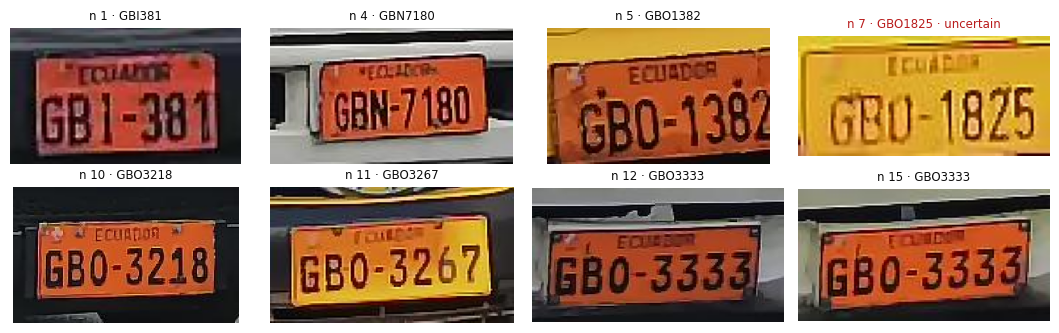

In [59]:
# 2.2 · Review-sheet images still awaiting a response.
SHOW_PENDING_REVIEW = True  # Unanswered review images, one per group of duplicates.

if SHOW_PENDING_REVIEW and savh_ref is not None:
    unique = savh_ref["duplicado_de_fila"].isna()
    added = (savh_ref["estado_gt"] == "camara_formato_valido") & (savh_ref["n_hoja"] != "")  # Unanswered disagreements.
    pending = savh_ref[unique & ((savh_ref["estado_gt"] == "sugerida_sin_confirmar") | added)]
    if pending.empty:
        print("All plates in the review sheet have a response.")
    else:
        pending = pending.assign(orden=pd.to_numeric(pending["n_hoja"], errors="coerce")).sort_values("orden")
        print(f"{len(pending)} images await confirmation in the review sheet (the number is the sheet n column; red: "
              "uncertain cases; blue: OCR disagreements retaining the camera reading).")
        pending = pending.head(min(8, int(SAVH_SAMPLE_SIZE or 8)))  # Display at most eight images per review.
        columns = 4
        rows = -(-len(pending) // columns)
        fig, axes = plt.subplots(rows, columns, figsize=(2.7 * columns, 1.7 * rows), squeeze=False)
        for ax in axes.flat:
            ax.axis("off")
        for ax, rec in zip(axes.flat, pending.itertuples(index=False)):
            ax.imshow(Image.open(SAVH_DIR / rec.image_path).convert("RGB"))
            doubtful = rec.chequeo_visual == "dudosa"
            disagreement = rec.estado_gt == "camara_formato_valido"
            tag = " · uncertain" if doubtful else (" · disagreement" if disagreement else "")
            ax.set_title(f"n {rec.n_hoja} · {rec.plate_gt}{tag}", fontsize=8.5,
                         color="#b91c1c" if doubtful else ("#1d4ed8" if disagreement else "#0b0b0b"))
        plt.tight_layout()
        plt.show()

In [60]:
# Reviewed labels for a future OCR split; these are not detector scenes.
# Keep these crops out of a reserved test: separate by vehicle/session and image hash.
ocr_reviewed=pd.DataFrame()
if savh_ref is not None:
    accepted=savh_ref['estado_gt'].isin(['confirmada','corregida_por_revisor'])
    ocr_reviewed=savh_ref[accepted & savh_ref['duplicado_de_fila'].isna()].copy()
    ocr_reviewed=ocr_reviewed[ocr_reviewed['plate_gt'].map(has_plate_format)]
    ocr_reviewed.to_csv(OCR_RESULTS_DIR/'ecuador_ocr_etiquetas_revisadas.csv',index=False)
    print("Unique crops with a confirmed transcription:",len(ocr_reviewed))

Unique crops with a confirmed transcription: 0


## 3. Modeling and experimental decision rule
### 3.1 Train RT-DETRv2-S on Ecuador scenes (optional)

The six supplied images are already split and annotated in GitHub. After the audit in 1.2 passes, enable `RUN_TRAIN_ECUADOR=True` and rerun this cell.
Use at most 30 epochs, patience 8, and seed 2; select the checkpoint with the lowest
validation loss. The test split is not involved. Transformers weights and OpenVINO IR are
saved under `WORK_DIR/models/detector/rtdetrv2_s/seed_2/`, without replacing the private USA
checkpoint or the application's checkpoint.

OpenVINO IR is for inference; continuing USA training requires the original Transformers
weights. If `TRAINING_MODEL_SOURCE` retains its initial value, fine-tuning starts from the
specified general plate checkpoint rather than the USA weights. The cell adapts Transformers
arguments to the installed version and does not unconditionally depend on `warmup_ratio`
or `save_safetensors`.

Selection uses validation loss, not mAP. The held-out development test and Ecuador calibration remain
pending until run with their corresponding references.

With only four training images, overfitting is expected. Validation contains one image; use this run to verify the workflow. Add diverse Ecuador scenes and negative images before drawing deployment conclusions. Enable Drive persistence in 0.2 to retain training outputs across Colab resets.

In [61]:
def training_arguments_ecuador(TrainingArguments,total_steps):
    supported=inspect.signature(TrainingArguments).parameters
    values=dict(output_dir=str(TRAIN_RUN_DIR),num_train_epochs=EPOCHS,
        learning_rate=5e-5,weight_decay=1e-4,per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=BATCH_SIZE,save_strategy='epoch',save_total_limit=2,
        load_best_model_at_end=True,metric_for_best_model='eval_loss',greater_is_better=False,
        remove_unused_columns=False,dataloader_num_workers=2,seed=TRAIN_SEED,
        data_seed=TRAIN_SEED,report_to='none',logging_steps=25)
    values['eval_strategy' if 'eval_strategy' in supported else 'evaluation_strategy']='epoch'
    if 'warmup_ratio' in supported: values['warmup_ratio']=0.05
    elif 'warmup_steps' in supported: values['warmup_steps']=max(1,math.ceil(total_steps*0.05))
    if 'save_safetensors' in supported: values['save_safetensors']=True
    values['prediction_loss_only'] = True
    if 'eval_do_concat_batches' in supported: values['eval_do_concat_batches'] = False
    return values

if RUN_TRAIN_ECUADOR:
    import torch
    from transformers import AutoImageProcessor,RTDetrV2ForObjectDetection,TrainingArguments,Trainer,EarlyStoppingCallback
    from src.train import CocoPlateDataset,detection_collator
    from src.export_openvino import export_openvino_model
    if not DATA_READY:
        raise RuntimeError('Run the COCO preparation and audit in 1.2 first.')
    COCO_AUDIT = audit_coco_dataset(ECUADOR_COCO_DIR)
    display(pd.DataFrame(COCO_AUDIT['splits']))
    if (MODEL_OUTPUT_DIR/'openvino/openvino_model.xml').exists() or (MODEL_OUTPUT_DIR/'transformers/config.json').exists():
        raise FileExistsError("An Ecuador candidate already exists. Use different MODEL_OUTPUT_DIR and TRAIN_RUN_DIR values for a new run.")
    from transformers import set_seed
    set_seed(TRAIN_SEED)
    processor=AutoImageProcessor.from_pretrained(str(TRAINING_MODEL_SOURCE),trust_remote_code=False,use_fast=False)
    model=RTDetrV2ForObjectDetection.from_pretrained(str(TRAINING_MODEL_SOURCE),trust_remote_code=False)
    if model.config.num_labels!=1: raise ValueError("The initial checkpoint must have exactly one plate class.")
    model.config.id2label={0:'license_plate'};model.config.label2id={'license_plate':0}
    train_data=CocoPlateDataset(ECUADOR_COCO_DIR,'train',processor)
    val_data=CocoPlateDataset(ECUADOR_COCO_DIR,'val',processor)
    total_steps=math.ceil(len(train_data)/BATCH_SIZE)*EPOCHS
    options=training_arguments_ecuador(TrainingArguments,total_steps)
    options['fp16']=torch.cuda.is_available()
    args=TrainingArguments(**options)
    trainer=Trainer(model=model,args=args,train_dataset=train_data,eval_dataset=val_data,
        data_collator=partial(detection_collator,image_processor=processor),processing_class=processor,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE)])
    trainer.train()
    transformers_dir=MODEL_OUTPUT_DIR/'transformers'
    trainer.save_model(str(transformers_dir));processor.save_pretrained(str(transformers_dir))
    manifest={'country':'ecuador','architecture':'RT-DETRv2-S','seed':TRAIN_SEED,
        'training_source':str(TRAINING_MODEL_SOURCE),'dataset_dir':str(ECUADOR_COCO_DIR),
        'dataset_sha256':COCO_AUDIT['dataset_sha256'],'dataset_scope':'six_photo_development',
        'epochs_completed':float(trainer.state.epoch or 0),
        'epochs_requested':EPOCHS,'early_stopping_patience':PATIENCE,
        'checkpoint_selection':'validation eval_loss','best_checkpoint':trainer.state.best_model_checkpoint,
        'detector_threshold':DETECTOR_THRESHOLD,'ocr_threshold':OCR_THRESHOLD,'independent_test_evaluated':False}
    openvino_xml=export_openvino_model(transformers_dir,MODEL_OUTPUT_DIR/'openvino',image_size=640)
    openvino_dir=Path(openvino_xml).parent
    for directory in (transformers_dir,openvino_dir):
        (directory/'sirap_training.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
    persist_tree_to_drive(MODEL_OUTPUT_DIR, DRIVE_ROOT / 'models/ecuador/detector/rtdetrv2_s/seed_2')
    print("Ecuador candidate saved to",MODEL_OUTPUT_DIR,"; not published or activated automatically.")
else:
    print("Training prepared. RUN_TRAIN_ECUADOR=False: no training ran and no weights were replaced.")

,split,images,plates,negative_images
0,train,4,9,0
1,val,1,1,0
2,test,1,1,0


preprocessor_config.json:   0%|          | 0.00/527 [00:00<?, ?B/s]

[transformers] The `use_fast` parameter is deprecated and will be removed in a future version. Use `backend="torchvision"` instead of `use_fast=True`, or `backend="pil"` instead of `use_fast=False`.


config.json:   0%|          | 0.00/2.57k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 80.5MB            

model.safetensors: downloading bytes:           |  0.00B            

... (33 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/529 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.
/usr/local/lib/python3.13/dist-packages/transformers/models/rt_detr/modeling_rt_detr_resnet.py:108: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if num_channels != self.num_channels:
/usr/local/lib/python3.13/dist-packages/transformers/integrations/sdpa_attention.py:140: TracerWarnin

Ecuador candidate saved to /content/SIRAP_workspace/ecuador/models/detector/rtdetrv2_s/seed_2 ; not published or activated automatically.


### 3.2 Model selection and camera requirements

This cell defines the selection; **loading happens in 4**. With `USE_ECUADOR_TRAINED_MODEL=True`,
it first searches for the candidate from 3.1 under
`WORK_DIR/models/detector/rtdetrv2_s/seed_2/openvino/`, then under
`models/ecuador/detector/rtdetrv2_s/openvino/` in the GitHub clone. It checks XML, BIN,
the OpenVINO manifest, and a training manifest identifying `country="ecuador"`.

If this selection is disabled, the Ecuador configuration can load the application's verified
shared checkpoint. Its secret retains the existing name `SIRAP_USA_MODEL_TOKEN`; configure
it in Colab Secrets. Alternatively, `USE_BASE_MODEL_FOR_SMOKE=True` exports the initial
checkpoint to a technical-test folder in the Ecuador workspace. Neither alternative is
labeled as Ecuador training or validation, nor can it publish an Ecuador candidate through 9.

Video uses detection 0.70 and minimum OCR confidence 0.94 to reproduce the experimental rule.
Camera recognition sessions additionally require a report **obtained by calibrating on Ecuador
validation data**, saved to `results/ecuador/metrics/rtdetr_ecuador_threshold_calibration.json`.
It must have this structure (values are illustrative, not results):

```json
{
  "country": "ecuador",
  "usable_for_inference": true,
  "threshold": 0.70,
  "checkpoint_sha256": {
    "openvino_model.xml": "Actual SHA256 of the evaluated XML",
    "openvino_model.bin": "Actual SHA256 of the evaluated BIN"
  }
}
```

Use the threshold and hashes produced by that validation; do not copy the example literally.
The exact IR contents are checked so moving the model from the workspace to GitHub or the
camera PC does not change its identity. The notebook does not create this report without
calibration and does not fill it using USA metrics.

In [62]:
pipeline = None
detector = None
MODEL_IS_COUNTRY_FINETUNED = False
MODEL_ORIGIN = 'not_loaded'
COUNTRY_IR_DIR = MODEL_OUTPUT_DIR / 'openvino'
COUNTRY_IR_XML = COUNTRY_IR_DIR / 'openvino_model.xml'
SHARED_IR_DIR = WORK_DIR / 'models/detector/technical_fallback/openvino'
DETECTOR_DIR = None
LIVE_THRESHOLD_RECORD_PATH = METRICS_DIR / 'rtdetr_ecuador_threshold_calibration.json'


def require_ecuador_ir(directory):
    """Check the four bundle files and their Ecuador identification."""
    directory = Path(directory)
    required = ('openvino_model.xml', 'openvino_model.bin', 'sirap_openvino.json', 'sirap_training.json')
    missing = [name for name in required if not (directory / name).is_file()]
    if missing:
        raise FileNotFoundError(f'Incomplete Ecuador IR at {directory}: {missing}')
    manifest = json.loads((directory / 'sirap_training.json').read_text(encoding='utf-8'))
    if manifest.get('country') != 'ecuador':
        raise ValueError("The training manifest does not identify an Ecuador candidate.")
    return directory


def validate_live_calibration(directory, record_path):
    """Bind the validated Ecuador threshold to the exact XML and BIN bytes."""
    directory = require_ecuador_ir(directory)
    record_path = Path(record_path)
    if not record_path.is_file():
        raise FileNotFoundError(f'Ecuador validation calibration is missing: {record_path}. See 3.2.')
    record = json.loads(record_path.read_text(encoding='utf-8'))
    threshold = record.get('threshold')
    if (record.get('country') != 'ecuador' or record.get('usable_for_inference') is not True
            or isinstance(threshold, bool) or not isinstance(threshold, (int, float))
            or not math.isfinite(threshold) or not 0 <= threshold <= 1):
        raise ValueError("The Ecuador calibration does not enable inference or has no valid threshold.")
    expected = record.get('checkpoint_sha256', {})
    for name in ('openvino_model.xml', 'openvino_model.bin'):
        actual = hashlib.sha256((directory / name).read_bytes()).hexdigest()
        if expected.get(name) != actual:
            raise ValueError(f'The calibration report does not match the selected IR: {name}.')
    return float(threshold), "Ecuador calibration on validation data"


print("Detector and OCR loading runs in 4 when RUN_INFERENCE=True.")
print("Local candidate:", COUNTRY_IR_DIR)
print("Published candidate:", REPO_MODEL_OUTPUT / 'openvino')
print("Required camera report:", LIVE_THRESHOLD_RECORD_PATH)

Detector and OCR loading runs in 4 when RUN_INFERENCE=True.
Local candidate: /content/SIRAP_workspace/ecuador/models/detector/rtdetrv2_s/seed_2/openvino
Published candidate: /content/SIRAP_USA_ECUADOR/models/ecuador/detector/rtdetrv2_s/openvino
Required camera report: /content/SIRAP_USA_ECUADOR/results/ecuador/metrics/rtdetr_ecuador_threshold_calibration.json


### 3.3 Authorized plate list

The local CSV at `WORK_DIR/authorized_plates.csv` contains one plate per line. If missing,
it is created empty so the pipeline can initialize. **The authorization list is maintained
in this CSV**, one plate per line. Readings close to an authorized plate require manual
verification. A simulated list for evaluating the SAVH rule (a separate experiment) would
be kept under `ocr/authorized_plates_simulada.csv` and would not replace this list.
`format_plate` converts plates to XXX-0000, so `GBA-1234`, `gba1234`, and `GBA 1234` represent
the same plate, as do `GMS-429` and `GMS-0429`.

In [63]:
# 3.3 · Authorized plate list. format_plate and clean_plate_text are defined in normalization (2.1).


def load_authorized_plates(path: Path) -> set:
    """CSV plates in XXX-0000 format; create an empty file if it is missing."""
    path.parent.mkdir(parents=True,exist_ok=True)
    if not path.exists():
        path.write_text("")
        print(f"Warning: {path} did not exist; an empty file was created. Add authorized plates, one per line.")
    with open(path, newline="") as f:
        plates = {format_plate(plate) for row in csv.reader(f) if row and row[0].strip() for plate,valid in [normalize_plate(row[0])] if valid}  # XXX-0000
    return plates - {"PLACA", "PLATE"}  # Handle a possible CSV header.


def edit_distance_leq_1(a: str, b: str) -> bool:
    """True if plates differ by at most one character (Levenshtein ≤ 1): a possible misreading of an authorized plate."""
    if abs(len(a) - len(b)) > 1:
        return False
    return Levenshtein.distance(a, b) <= 1


AUTHORIZED_PLATES = load_authorized_plates(AUTHORIZED_LIST_PATH)
print(f"{len(AUTHORIZED_PLATES)} authorized plates in {AUTHORIZED_LIST_PATH}")

0 authorized plates in /content/SIRAP_workspace/ecuador/authorized_plates.csv


### 3.4 Experimental decision rule

The CSV list is used only within this notebook. Low confidence, invalid format, or an
approximate match requires manual review. Neither SRI information nor an owner name grants
access. This experiment **does not actuate a barrier** or write operations to the application.

In [64]:
def decidir_ecuador(reading):
    plate=reading.plate
    if not plate or not math.isfinite(reading.det_confidence) or not math.isfinite(reading.ocr_confidence) or reading.det_confidence<DETECTOR_THRESHOLD or reading.ocr_confidence<OCR_THRESHOLD:
        return 'VERIFICACION_MANUAL'
    if plate in AUTHORIZED_PLATES:return 'AUTORIZADO'
    if any(edit_distance_leq_1(plate,p) for p in AUTHORIZED_PLATES):return 'VERIFICACION_MANUAL'
    return 'NO_REGISTRADO'

## 4. Load the Ecuador OpenVINO IR

Integrated from USA section 13. With `RUN_INFERENCE=True`, load the Ecuador IR selected in
3.2 on CPU and prepare OCR with Ecuador patterns. A local bundle trained in 3.1 has priority
over the published bundle. Technical alternatives are selected explicitly in 0.2; they are
never presented as Ecuador training. Loading does not publish or activate application weights.
The detector does not directly load `.pt`, `.safetensors`, or ONNX weights for inference.

In [65]:
from src.export_openvino import export_openvino_model
from src.model import PlateDetector
from src.usa_pipeline import USAPipeline

pipeline = None
detector = None
MODEL_IS_COUNTRY_FINETUNED = False
MODEL_ORIGIN = 'not_loaded'
DETECTOR_DIR = None

if RUN_INFERENCE:
    if USE_ECUADOR_TRAINED_MODEL:
        if RESTORE_ECUADOR_IR_FROM_DRIVE:
            # Restore exactly this validated bundle before loading. Never relabel its origin.
            source = require_ecuador_ir(DRIVE_ECUADOR_IR)
            destination = MODEL_OUTPUT_DIR / 'openvino'
            if destination.exists():
                raise FileExistsError(f'An IR already exists: {destination}. Select it or use another output directory.')
            destination.parent.mkdir(parents=True, exist_ok=True)
            shutil.copytree(source, destination)
        candidates = (MODEL_OUTPUT_DIR / 'openvino', REPO_MODEL_OUTPUT / 'openvino')
        COUNTRY_IR_DIR = next((path for path in candidates if (path / 'openvino_model.xml').is_file()), None)
        if COUNTRY_IR_DIR is None:
            raise FileNotFoundError('No Ecuador candidate exists. Run training in 3.1 or explicitly restore a complete Ecuador IR bundle.')
        require_ecuador_ir(COUNTRY_IR_DIR)
        COUNTRY_IR_XML = COUNTRY_IR_DIR / 'openvino_model.xml'
        DETECTOR_DIR = COUNTRY_IR_DIR
        MODEL_IS_COUNTRY_FINETUNED = True
        MODEL_ORIGIN = 'ecuador_finetuned'
    elif USE_BASE_MODEL_FOR_SMOKE:
        DETECTOR_DIR = SHARED_IR_DIR
        if not (DETECTOR_DIR / 'openvino_model.xml').is_file():
            export_openvino_model(MODEL_ID, DETECTOR_DIR, image_size=IMAGE_SIZE)
        MODEL_ORIGIN = 'initial_checkpoint_technical_smoke'
    else:
        from src.utils import get_secret
        secret = get_secret('SIRAP_USA_MODEL_TOKEN')
        if secret:
            os.environ['SIRAP_USA_MODEL_TOKEN'] = secret
        pipeline = USAPipeline.from_config(COUNTRY_CONFIG).for_country('ecuador', PLATE_PATTERNS)
        detector = pipeline.detector
        DETECTOR_DIR = detector.model_path.parent
        MODEL_ORIGIN = 'shared_verified_checkpoint_ecuador_rules'

    if detector is None:
        detector = PlateDetector(checkpoint=DETECTOR_DIR, model_id=MODEL_ID, imgsz=IMAGE_SIZE,
                                 conf=DETECTOR_THRESHOLD, class_id=0, device='CPU', fallback_checkpoint=None)
        reader = RuntimeSelectedSerialReader(model_name=OCR_MODEL_NAME)
        pipeline = USAPipeline(detector, reader, country='ecuador', patterns=PLATE_PATTERNS)
    print("Loaded model:", detector.name)
    print("Trained specifically on Ecuador data:", MODEL_IS_COUNTRY_FINETUNED)
    print("Source:", MODEL_ORIGIN)
    print("OpenVINO devices:", detector.core.available_devices)
else:
    print("Loading is disabled. After training, enable RUN_INFERENCE and run 4 to load the IR.")

2026-11-16 22:32:33,471 | INFO | sirap.model | Detector cargado: RT-DETRv2-S · OpenVINO Runtime · /content/SIRAP_workspace/ecuador/models/detector/rtdetrv2_s/seed_2/openvino (CPU)


Loaded model: RT-DETRv2-S · OpenVINO Runtime · /content/SIRAP_workspace/ecuador/models/detector/rtdetrv2_s/seed_2/openvino
Trained specifically on Ecuador data: True
Source: ecuador_finetuned
OpenVINO devices: ['CPU', 'GPU']


## 5. Detector checks and COCO evaluation
### 5.1 OpenVINO smoke check

Integrated from USA section 14. A blank-image inference checks that the selected IR loads.
Accuracy is measured separately in 5.2 and 5.3 with actual bounding-box references.

In [66]:
if detector is None:
    print("Check pending: enable RUN_INFERENCE and run 4.")
else:
    blank_image = np.zeros((480, 640, 3), dtype=np.uint8)
    smoke_detections = detector.detect(blank_image, max_detections=20)
    print("OpenVINO inference completed.")
    print("Boxes returned for the blank image:", len(smoke_detections))
    print("This check only confirms that the model loads and runs; it does not measure accuracy.")

OpenVINO inference completed.
Boxes returned for the blank image: 0
This check only confirms that the model loads and runs; it does not measure accuracy.


### 5.2 COCO validation and candidate freeze

After training in 3.1, enable inference in 0.2 and load the Ecuador IR in 4.
Then enable `RUN_COCO_VALIDATION=True` and run this cell. It evaluates **only validation**,
reports standard COCO mAP50–95/AP50/AP75, and counts TP/FP/FN and precision/recall/F1
at the configured detection threshold (0.70 initially) and IoU 0.50.

AP uses a low score floor of 0.001 and COCO's standard maximum of 100 detections per image.
Precision and recall are computed from matches, not averaged interpolated AP samples.
No detections produces zero AP and false negatives when plates exist; all-negative AP is undefined.

This freezes the exact XML/BIN hashes, dataset fingerprint, and threshold for 5.3.
Any threshold changes must use validation only. The single validation image is insufficient
for a reliable camera calibration; this cell does not enable camera authorization.

In [67]:
COCO_VALIDATION_REPORT = True
if RUN_COCO_VALIDATION:
    from src.evaluate import evaluate_detector
    if not DATA_READY or detector is None or not MODEL_IS_COUNTRY_FINETUNED:
        raise RuntimeError('Audit the data, train an Ecuador candidate, and load it in 4 first.')
    selected_ir = require_ecuador_ir(DETECTOR_DIR)
    COCO_AUDIT = audit_coco_dataset(ECUADOR_COCO_DIR)
    validation_path = METRICS_DIR / f'{COCO_EVAL_RUN_ID}_validation.json'
    COCO_VALIDATION_REPORT = evaluate_detector(
        ECUADOR_COCO_DIR, country='ecuador', split='val', checkpoint=selected_ir,
        threshold=COCO_AP_CONFIDENCE_FLOOR, operating_threshold=DETECTOR_THRESHOLD,
        result_path=validation_path)
    plan = {'country': COUNTRY, 'run_id': COCO_EVAL_RUN_ID,
            'dataset_sha256': COCO_AUDIT['dataset_sha256'],
            'checkpoint_sha256': COCO_VALIDATION_REPORT['checkpoint_sha256'],
            'operating_threshold': DETECTOR_THRESHOLD, 'ap_floor': COCO_AP_CONFIDENCE_FLOOR,
            'scope': 'six_photo_development', 'selection_split': 'val'}
    (METRICS_DIR / f'{COCO_EVAL_RUN_ID}_test_plan.json').write_text(
        json.dumps(plan, indent=2), encoding='utf-8')
    display(pd.DataFrame([COCO_VALIDATION_REPORT]))
    persist_file_to_drive(validation_path, DRIVE_ROOT / 'results/ecuador/metrics' / validation_path.name)
else:
    print('COCO validation disabled. No accuracy metrics have been computed.')

2026-11-16 22:32:36,157 | INFO | sirap.model | Detector cargado: RT-DETRv2-S · OpenVINO Runtime · /content/SIRAP_workspace/ecuador/models/detector/rtdetrv2_s/seed_2/openvino (CPU)
2026-11-16 22:32:36,678 | INFO | sirap.evaluate | Detector RT-DETRv2-S/OpenVINO (val): {'map50_95': 0.0, 'map50': 0.0, 'map75': 0.0, 'map50_95_small': None, 'map50_95_medium': 0.0, 'map50_95_large': None, 'images': 1, 'plates': 1, 'predictions': 300, 'tp': 0, 'fp': 0, 'fn': 1, 'ignored_predictions': 0, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'operating_threshold': 0.7, 'operating_iou': 0.5, 'max_detections_per_image': 100, 'metric_note': 'AP uses all supplied scores; P/R/F1 use matches at the stated confidence and IoU. Undefined AP/recall are null; precision with no predictions is zero.', 'country': 'ecuador', 'detector': 'RT-DETRv2-S', 'inference_runtime': 'OpenVINO Runtime', 'checkpoint': '/content/SIRAP_workspace/ecuador/models/detector/rtdetrv2_s/seed_2/openvino/openvino_model.xml', 'checkpoint_sha256

,map50_95,map50,map75,map50_95_small,map50_95_medium,map50_95_large,images,plates,predictions,tp,...,threshold_for_ap,split_sha256,source_categories,evaluated_classes,dataset_scope,imagenes,placas,map50_95_pequenas,map50_95_medianas,map50_95_grandes
0,0.0,0.0,0.0,None,0.0,None,1,1,300,0,...,0.001,bfb06ccf9133479bcf300e779a9e4e67b19b7ea373a57f...,1,[license_plate],development_only,1,1,None,0.0,None


### 5.3 Held-out COCO development test

After candidate selection and threshold choice are frozen in 5.2, enable
`RUN_FINAL_TEST_EVALUATION=True` and run this cell once. Only the held-out white
Chevrolet image (`ecuador_02.jpeg`) is evaluated. It is never used in training,
early stopping, or threshold selection. The first and third supplied photos remain together in train.

The test requires the frozen candidate, dataset, and threshold to match. Existing test reports
are preserved. Use a new run identifier for a separate documented experiment; repeatedly
choosing models from this test would invalidate its held-out status. A one-image positive test
is a development check, not an independent field acceptance study. OCR accuracy requires separate transcriptions.

In [68]:
COCO_TEST_REPORT = True
if RUN_FINAL_TEST_EVALUATION:
    from src.evaluate import evaluate_detector
    if not DATA_READY or detector is None or not MODEL_IS_COUNTRY_FINETUNED:
        raise RuntimeError('Complete 1.2, 3.1, 4, and 5.2 first.')
    plan_path = METRICS_DIR / f'{COCO_EVAL_RUN_ID}_test_plan.json'
    if not plan_path.is_file():
        raise FileNotFoundError('Freeze the candidate and threshold with validation in 5.2 first.')
    plan = json.loads(plan_path.read_text(encoding='utf-8'))
    current_audit = audit_coco_dataset(ECUADOR_COCO_DIR)
    selected_ir = require_ecuador_ir(DETECTOR_DIR)
    current_hashes = {name: hashlib.sha256((selected_ir / name).read_bytes()).hexdigest()
                      for name in ('openvino_model.xml', 'openvino_model.bin')}
    if (plan.get('country') != COUNTRY or plan.get('run_id') != COCO_EVAL_RUN_ID
            or plan.get('dataset_sha256') != current_audit['dataset_sha256']
            or plan.get('checkpoint_sha256') != current_hashes
            or plan.get('operating_threshold') != DETECTOR_THRESHOLD
            or plan.get('ap_floor') != COCO_AP_CONFIDENCE_FLOOR):
        raise ValueError('The candidate, dataset, or thresholds changed after validation.')
    test_path = METRICS_DIR / f'{COCO_EVAL_RUN_ID}_test.json'
    if test_path.exists():
        raise FileExistsError(f'The test was already recorded: {test_path}')
    COCO_TEST_REPORT = evaluate_detector(
        ECUADOR_COCO_DIR, country='ecuador', split='test', checkpoint=selected_ir,
        threshold=COCO_AP_CONFIDENCE_FLOOR, operating_threshold=DETECTOR_THRESHOLD,
        result_path=test_path)
    display(pd.DataFrame([COCO_TEST_REPORT]))
    persist_file_to_drive(test_path, DRIVE_ROOT / 'results/ecuador/metrics' / test_path.name)
else:
    print('Held-out COCO test disabled. No test metrics have been computed.')

2026-11-16 22:32:37,957 | INFO | sirap.model | Detector cargado: RT-DETRv2-S · OpenVINO Runtime · /content/SIRAP_workspace/ecuador/models/detector/rtdetrv2_s/seed_2/openvino (CPU)
2026-11-16 22:32:38,454 | INFO | sirap.evaluate | Detector RT-DETRv2-S/OpenVINO (test): {'map50_95': 0.6999999999999998, 'map50': 0.9999999999999999, 'map75': 0.9999999999999999, 'map50_95_small': None, 'map50_95_medium': 0.6999999999999998, 'map50_95_large': None, 'images': 1, 'plates': 1, 'predictions': 300, 'tp': 0, 'fp': 0, 'fn': 1, 'ignored_predictions': 0, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'operating_threshold': 0.7, 'operating_iou': 0.5, 'max_detections_per_image': 100, 'metric_note': 'AP uses all supplied scores; P/R/F1 use matches at the stated confidence and IoU. Undefined AP/recall are null; precision with no predictions is zero.', 'country': 'ecuador', 'detector': 'RT-DETRv2-S', 'inference_runtime': 'OpenVINO Runtime', 'checkpoint': '/content/SIRAP_workspace/ecuador/models/detector/rtdet

,map50_95,map50,map75,map50_95_small,map50_95_medium,map50_95_large,images,plates,predictions,tp,...,threshold_for_ap,split_sha256,source_categories,evaluated_classes,dataset_scope,imagenes,placas,map50_95_pequenas,map50_95_medianas,map50_95_grandes
0,0.7,1.0,1.0,None,0.7,None,1,1,300,0,...,0.001,f0b8369a3dfa266544173df26a98885e12006319405689...,1,[license_plate],development_only,1,1,None,0.7,None


## 6. Complete system: video demonstration pipeline
### 6.1 Video source

Select your own Ecuador recording through `SIRAP_ECUADOR_VIDEO_PATH` or `VIDEO_PATH`.
The default is `datasets/ecuador/videos/demo_ecuador.mp4` in the GitHub clone. If it is missing,
the notebook does not invent that file or download a video from another country. For your
own Drive video, set `VIDEO_ID` and enable `DOWNLOAD_DEMO_VIDEO`; it will be downloaded under
`WORK_DIR/videos/`. A demonstration video is not an independent test.

In [69]:
VIDEO_ID = ''  # ID of your own Ecuador video; empty by default.
VIDEO_PATH = Path(os.environ.get('SIRAP_ECUADOR_VIDEO_PATH', str(DATASET_DIR / 'videos/demo_ecuador.mp4')))
DOWNLOAD_DEMO_VIDEO = False
if RUN_VIDEO and DOWNLOAD_DEMO_VIDEO:
    if not VIDEO_ID:
        raise ValueError("Set VIDEO_ID to your Ecuador recording before downloading.")
    VIDEO_PATH = WORK_DIR / 'videos/demo_ecuador.mp4'
    VIDEO_PATH.parent.mkdir(parents=True, exist_ok=True)
    if not VIDEO_PATH.is_file():
        import gdown
        downloaded = gdown.download(id=VIDEO_ID, output=str(VIDEO_PATH), quiet=False)
        if not downloaded or not VIDEO_PATH.is_file():
            raise FileNotFoundError("Could not download the specified Ecuador video.")

### 6.2 Logging and sampling

Sample one frame every 2.5 seconds, with **at most eight frames** by default. Every plate
detected by the pipeline is recorded with country, model, and confidence; transcriptions
are not fabricated for unreadable plates. CSV files remain under `WORK_DIR/registros_csv/`.

In [70]:
VIDEO_SAMPLE_SECONDS=2.5
MAX_VIDEO_FRAMES=8
VIDEO_RESULTS_PATH=WORK_DIR/'decisions_rtdetr_ecuador.csv'

### 6.3 CSV authorizations and SRI verification

The pipeline obtains authorizations exclusively from `authorized_plates.csv`, maintained
locally with one plate per line. If missing, the file is created empty. Plates are normalized
to `XXX-0000`: an authorized plate receives `AUTORIZADO` (authorized), a one-character near
match receives `VERIFICACION_MANUAL` (manual verification), and other plates receive
`NO_REGISTRADO` (not registered). These status codes retain their existing spelling.

Readings, SRI lookups, and public-name lookups are stored as CSV files under `registros_csv/`
in temporary session storage. External synchronization remains disabled. This integration
does not write operational CSV files to GitHub or change application authorizations.

**Optional SRI lookup.** With `SRI_VERIFICAR=True`, each valid plate is queried in the
background using the public service behind the SRI page for amounts due by plate: make,
model, year, country, last paid year, and outstanding amounts. If an older plate with a
leading zero is not found, the lookup retries with its three original digits. At most
one request is sent every 2 seconds; successful responses are reused for 24 hours. Errors
are logged to `registros_csv/consultas_sri.csv` so they can be retried in another run.
SRI does not return the owner's name, and its response does not change the access decision.

Working CSV files remain under `WORK_DIR/registros_csv/` and are not published automatically.
Section 0 mounts Google Drive only when `PERSIST_OUTPUTS_TO_DRIVE` is enabled; SRI/owner CSV
files still remain local.

In [71]:
# ===================== 6.3 · CSV files + automatic SRI verification =====================
import base64
import csv
import datetime as dt
import io
import json
import os
import re
import threading
import time
import unicodedata
import uuid
from concurrent.futures import ThreadPoolExecutor
from urllib.parse import quote

import requests

# SIRAP stores the authorization list and pipeline results in CSV files.
# Working CSV files remain in temporary session storage. GitHub synchronization is disabled.
PIPELINE_CSV_DIR = WORK_DIR / "registros_csv"
PIPELINE_CSV_DIR.mkdir(parents=True, exist_ok=True)
CSV_PATHS = {
    "lecturas": PIPELINE_CSV_DIR / "lecturas.csv",
    "consultas_sri": PIPELINE_CSV_DIR / "consultas_sri.csv",
    "propietarios_vehiculo": PIPELINE_CSV_DIR / "propietarios.csv",
    "historial_propietarios": PIPELINE_CSV_DIR / "historial_propietarios.csv",
    "consultas_propietario": PIPELINE_CSV_DIR / "consultas_propietario.csv",
}

SRI_VERIFICAR = False  # Enable only when you intend to query the service.
SRI_CONSULTAR_RUBROS = True
SRI_CACHE_HOURS = 24
SRI_MIN_INTERVAL_S = 2.0
SRI_TIMEOUT_S = 15
SRI_REST = "https://srienlinea.sri.gob.ec/sri-matriculacion-vehicular-recaudacion-servicio-internet/rest"
SRI_HEADERS = {"Accept": "application/json", "User-Agent": "ProyectoIntegrador-ALPR/1.0 (academic use)"}



def now_ec() -> dt.datetime:
    """Ecuador time (UTC−5), without a timezone suffix to retain the record format."""
    return dt.datetime.now(dt.timezone(dt.timedelta(hours=-5))).replace(tzinfo=None, microsecond=0)


def ascii_text(text) -> str:
    """OpenCV cannot draw accents: 'LOGÍSTICA ÑANDÚ' → 'LOGISTICA NANDU'."""
    return unicodedata.normalize("NFKD", str(text)).encode("ascii", "ignore").decode()


class CsvPipelineStore:
    """CSV persistence in temporary Colab session storage."""

    def __init__(self):
        self.lock = threading.RLock()
        for table, path in CSV_PATHS.items():
            if not path.exists():
                path.parent.mkdir(parents=True, exist_ok=True)
                path.write_text("", encoding="utf-8")

    def read(self, table: str) -> pd.DataFrame:
        if table not in CSV_PATHS:
            raise ValueError(f"Unknown CSV: {table}")
        path = CSV_PATHS[table]
        if not path.exists() or path.stat().st_size == 0:
            return pd.DataFrame()
        try:
            return pd.read_csv(path, keep_default_na=False)
        except pd.errors.EmptyDataError:
            return pd.DataFrame()

    def _write_rows(self, table: str, rows: list[dict]) -> None:
        path = CSV_PATHS[table]
        columns = list(dict.fromkeys([key for row in rows for key in row]))
        temp = path.with_suffix(path.suffix + ".tmp")
        with temp.open("w", encoding="utf-8-sig", newline="") as stream:
            if columns:
                writer = csv.DictWriter(stream, fieldnames=columns, extrasaction="ignore", lineterminator="\n")
                writer.writeheader()
                writer.writerows(rows)
        os.replace(temp, path)

    def insert(self, table: str, row: dict) -> None:
        if table not in CSV_PATHS:
            raise ValueError(f"Unknown CSV: {table}")
        with self.lock:
            current = self.read(table).to_dict("records")
            current.append({key: "" if value is None else value for key, value in row.items()})
            self._write_rows(table, current)

    def replace(self, table: str, rows: list[dict]) -> None:
        if table not in CSV_PATHS:
            raise ValueError(f"Unknown CSV: {table}")
        with self.lock:
            self._write_rows(table, rows)

    def latest_consulta(self, placa: str, max_age_hours: float):
        rows = self.read("consultas_sri")
        if rows.empty or "placa" not in rows or "consultado_en" not in rows:
            return None
        rows = rows[rows["placa"].astype(str).eq(placa)].copy()
        rows["_fecha"] = pd.to_datetime(rows["consultado_en"], errors="coerce")
        cutoff = now_ec() - dt.timedelta(hours=max_age_hours)
        rows = rows[rows["_fecha"].notna() & (rows["_fecha"] >= cutoff)]
        if "error" in rows:
            rows = rows[rows["error"].astype(str).eq("")]
        if rows.empty:
            return None
        record = rows.sort_values("_fecha").iloc[-1].drop(labels=["_fecha"]).to_dict()
        for key in ("encontrado", "matricula_al_dia"):
            if key in record and isinstance(record[key], str):
                record[key] = record[key].strip().lower() in ("true", "1", "sí", "si")
        for key in ("codigo_vehiculo", "ultimo_anio_pagado", "rubros_pendientes"):
            if key in record:
                try:
                    record[key] = int(float(record[key]))
                except (TypeError, ValueError):
                    record[key] = None
        for key in ("total_pendiente",):
            if key in record:
                try:
                    record[key] = float(record[key])
                except (TypeError, ValueError):
                    record[key] = None
        return record

    def owner(self, placa: str):
        rows = self.read("propietarios_vehiculo")
        if rows.empty or "placa" not in rows:
            return None
        matches = rows[rows["placa"].astype(str).eq(placa)]
        return None if matches.empty else matches.iloc[-1].to_dict()

    def owner_rows(self) -> list[dict]:
        return self.read("propietarios_vehiculo").to_dict("records")

    def upsert_owner(self, placa: str, nombre: str, fuente: str, fecha) -> tuple[str, str | None]:
        with self.lock:
            rows = self.read("propietarios_vehiculo").to_dict("records")
            existing = next((row for row in rows if str(row.get("placa")) == placa), None)
            anterior = existing.get("nombre") if existing else None
            if existing is None:
                rows.append({"placa": placa, "nombre": nombre, "fuente": fuente,
                             "consultado_en": fecha, "actualizado_en": fecha})
                estado = "insertado"
            elif anterior != nombre:
                existing.update({"nombre": nombre, "fuente": fuente,
                                 "consultado_en": fecha, "actualizado_en": fecha})
                estado = "actualizado"
            else:
                existing.update({"fuente": fuente, "consultado_en": fecha})
                estado = "sin_cambios"
            self._write_rows("propietarios_vehiculo", rows)
            if estado != "sin_cambios":
                self.insert("historial_propietarios", {"placa": placa, "cambiado_en": fecha,
                             "anterior": anterior, "nuevo": nombre, "fuente": fuente})
            return estado, anterior

    def clear_readings(self, corrida: str, video: str) -> None:
        rows = self.read("lecturas")
        if rows.empty:
            return
        keep = rows[~((rows.get("corrida", "").astype(str) == corrida)
                      & (rows.get("video", "").astype(str) == video))]
        self.replace("lecturas", keep.to_dict("records"))

    def verified_readings(self) -> pd.DataFrame:
        reads = self.read("lecturas")
        if reads.empty:
            return reads
        sri = self.read("consultas_sri")
        owners = self.read("propietarios_vehiculo")
        if not sri.empty and "placa" in sri:
            sri = sri.sort_values("consultado_en").drop_duplicates("placa", keep="last")
            rename = {key: f"sri_{key}" for key in sri.columns if key != "placa"}
            reads = reads.merge(sri.rename(columns=rename), on="placa", how="left")
        if not owners.empty and "placa" in owners:
            owners = owners.drop_duplicates("placa", keep="last").rename(columns={
                "nombre": "propietario_nombre", "fuente": "propietario_fuente",
                "consultado_en": "propietario_consultado_en", "actualizado_en": "propietario_actualizado_en"})
            reads = reads.merge(owners, on="placa", how="left")
        reads["registrado_csv"] = reads.get("autorizado_por_csv", False)
        return reads

    def save(self) -> None:
        """Keep CSV files in temporary Colab storage, without GitHub synchronization."""
        try:
            self._sync_github()
        except Exception as error:
            print(f"CSV files saved in temporary session storage; GitHub synchronization failed: {type(error).__name__}: {error}")

    def _sync_github(self) -> None:
        # Synchronization explicitly disabled at the user's request.
        return


# The exceptions/allowlist CSV is the only source of authorized plates.
# One-character near matches receive VERIFICACION_MANUAL in decide_access.
_csv_plates = load_authorized_plates(AUTHORIZED_LIST_PATH)
AUTHORIZED_PLATES = set(_csv_plates)
CSV_AUTORIZADAS = set(AUTHORIZED_PLATES)


def panel_detail(placa: str):
    if not placa:
        return None
    planta = "authorized by CSV" if placa in AUTHORIZED_PLATES else "not authorized in CSV"
    sri_text = sri.short(placa)
    return f"{planta} | {sri_text}" if sri_text else planta

_sri_session = requests.Session()
_sri_session.headers.update(SRI_HEADERS)


def _sri_get(url: str, params: dict):
    """GET with 2 retries for connection failures or server errors (5xx)."""
    for attempt in range(3):
        try:
            response = _sri_session.get(url, params=params, timeout=SRI_TIMEOUT_S)
            if response.status_code >= 500:
                raise requests.HTTPError(f"HTTP {response.status_code}", response=response)
            if response.status_code in (204, 404):
                return None, response.text
            response.raise_for_status()
            text = response.text.strip()
            return (json.loads(text) if text else None), text
        except (requests.ConnectionError, requests.Timeout, requests.HTTPError) as error:
            is_server_error = error.response is None or error.response.status_code >= 500
            if attempt == 2 or not is_server_error:
                raise
            time.sleep(2 * (attempt + 1))


def consultar_sri(placa: str) -> dict:
    """Query the public SRI service; it does not return owner information."""
    url = f"{SRI_REST}/BaseVehiculo/obtenerPorNumeroPlacaOPorNumeroCampvOPorNumeroCpn"
    found = lambda value: isinstance(value, dict) and bool(value.get("numeroPlaca") or value.get("codigoVehiculo"))
    compacta = placa.replace("-", "")
    vehiculo, texto = _sri_get(url, {"numeroPlacaCampvCpn": compacta})
    if not found(vehiculo) and re.fullmatch(r"[A-Z]{3}0[0-9]{3}", compacta):
        time.sleep(1)
        vehiculo, texto = _sri_get(url, {"numeroPlacaCampvCpn": compacta[:3] + compacta[4:]})
    resultado = {"placa": placa, "encontrado": False, "respuesta_vehiculo": texto[:4000] or None}
    if not found(vehiculo):
        resultado["alerta"] = "plate not found in SRI (possible OCR misreading)"
        return resultado
    try:
        ultimo = int(vehiculo.get("ultimoAnioPagado"))
    except (TypeError, ValueError):
        ultimo = None
    resultado.update(
        encontrado=True, codigo_vehiculo=vehiculo.get("codigoVehiculo"), camv_cpn=vehiculo.get("numeroCamvCpn"),
        marca=vehiculo.get("descripcionMarca"), modelo=vehiculo.get("descripcionModelo"),
        anio_modelo=vehiculo.get("anioAuto"), pais=vehiculo.get("descripcionPais"), clase=vehiculo.get("nombreClase"),
        servicio=vehiculo.get("descripcionServicio"), canton=vehiculo.get("descripcionCanton"),
        estado_exoneracion=vehiculo.get("estadoExoneracion"), ultimo_anio_pagado=ultimo,
        matricula_al_dia=None if ultimo is None else ultimo >= now_ec().year,
        prohibido_enajenar=None if vehiculo.get("prohibidoEnajenar") is None else str(vehiculo["prohibidoEnajenar"]))
    alertas = [] if resultado["matricula_al_dia"] is not False else [f"unpaid year {now_ec().year} (last paid: {ultimo})"]
    if SRI_CONSULTAR_RUBROS and vehiculo.get("codigoVehiculo"):
        try:
            rubros, texto_rubros = _sri_get(f"{SRI_REST}/ConsultaRubros/obtenerPorCodigoVehiculo",
                                            {"codigoVehiculo": vehiculo["codigoVehiculo"]})
            resultado["respuesta_rubros"] = texto_rubros[:4000] or None
            if rubros is None or isinstance(rubros, list):
                items = rubros or []
                resultado["rubros_pendientes"] = len(items)
                valores = [item.get("valor") for item in items if isinstance(item, dict)]
                if items and len(valores) == len(items) and all(isinstance(value, (int, float)) for value in valores):
                    resultado["total_pendiente"] = float(sum(valores))
                if items:
                    alertas.append("1 outstanding amount" if len(items) == 1 else f"{len(items)} outstanding amounts")
        except Exception as error:
            resultado["respuesta_rubros"] = f"error: {type(error).__name__}: {error}"[:500]
    resultado["alerta"] = "; ".join(alertas) or None
    return resultado


class SRIVerifier:
    """Query SRI in the background and save responses to CSV."""

    def __init__(self, store_: CsvPipelineStore):
        self.store = store_
        self.pool = ThreadPoolExecutor(max_workers=1, thread_name_prefix="sri")
        self.results, self.futures, self.lock, self.last_call = {}, {}, threading.Lock(), 0.0

    def submit(self, placa: str) -> None:
        if not SRI_VERIFICAR or not placa:
            return
        with self.lock:
            if placa in self.results or placa in self.futures:
                return
            cached = self.store.latest_consulta(placa, SRI_CACHE_HOURS)
            if cached is not None:
                self.results[placa] = cached
                return
            self.futures[placa] = self.pool.submit(self._consultar, placa)

    def _consultar(self, placa: str) -> dict:
        espera = SRI_MIN_INTERVAL_S - (time.monotonic() - self.last_call)
        if espera > 0:
            time.sleep(espera)
        self.last_call = time.monotonic()
        try:
            resultado = consultar_sri(placa)
        except Exception as error:
            resultado = {"placa": placa, "encontrado": None, "error": f"{type(error).__name__}: {error}"[:500]}
        resultado["consultado_en"] = now_ec()
        self.store.insert("consultas_sri", resultado)
        with self.lock:
            self.results[placa] = resultado
            self.futures.pop(placa, None)
        return resultado

    def wait(self) -> None:
        with self.lock:
            jobs = list(self.futures.values())
        for future in jobs:
            future.result()

    def summary(self, placa: str):
        if not SRI_VERIFICAR or not placa:
            return None
        result = self.results.get(placa)
        if result is None:
            return "SRI: querying..." if placa in self.futures else None
        if result.get("error"):
            return "SRI: no response"
        if not result.get("encontrado"):
            return "SRI: plate not found"
        vehicle = ascii_text(f"{result.get('marca') or ''} {result.get('modelo') or ''}").strip()[:26]
        estado = "up to date" if result.get("matricula_al_dia") else f"last payment {result.get('ultimo_anio_pagado')}"
        return f"{vehicle} {result.get('anio_modelo') or ''} | {estado}"

    def short(self, placa: str):
        if not SRI_VERIFICAR or not placa:
            return None
        result = self.results.get(placa)
        if result is None:
            return "SRI: querying..." if placa in self.futures else None
        if result.get("error"):
            return "SRI: no response"
        if not result.get("encontrado"):
            return "SRI: plate not found"
        marca = ascii_text(result.get("marca") or "").strip()[:14]
        estado = "up to date" if result.get("matricula_al_dia") else f"last payment {result.get('ultimo_anio_pagado')}"
        return f"SRI {marca} {estado}".replace("  ", " ")


def guardar_lectura(reading,frame_index,seconds,corrida,video):
    """Local RT-DETR Ecuador record; no YOLO fields or models."""
    store.insert('lecturas',dict(event_id=str(uuid.uuid4()),registrado_en=now_ec(),
        modelo=reading.detector,country='ecuador',corrida=corrida,video=Path(video).name,
        frame_index=frame_index,segundo_video=seconds,placa=reading.plate or '',
        texto_ocr=reading.plate_raw,formato_valido=bool(reading.plate),
        ocr_conf=reading.ocr_confidence,det_conf=reading.det_confidence,
        estado_acceso=decidir_ecuador(reading),autorizado_por_csv=reading.plate in AUTHORIZED_PLATES))


store = CsvPipelineStore()
sri = SRIVerifier(store)
print(f"Authorizations loaded from {AUTHORIZED_LIST_PATH.name}: {len(AUTHORIZED_PLATES)}")
print("Readings and lookups saved in session CSV files:", PIPELINE_CSV_DIR)

Authorizations loaded from authorized_plates.csv: 0
Readings and lookups saved in session CSV files: /content/SIRAP_workspace/ecuador/registros_csv


### 6.4 Owner name (optional public lookup and local records)

This section retains the attachment's integration with the public [EcuadorLegalOnline form](https://www.ecuadorlegalonline.com/consultas/agencia-nacional-de-transito/consultar-a-quien-pertenece-un-vehiculo-por-placa-ant/)
**only if the provider permits the lookup and the name is visible without payment**. This
edit did not verify that the website still provides that information. If restricted, local
records are retained. The integration does not open the full-report option (`VER REPORTE
COMPLETO`) or try to obtain identity/tax numbers, addresses, or contact details. CAPTCHAs,
restrictions, hidden data, or errors **do not overwrite** stored information. Before saving
a name, the returned plate must match the plate queried.

**Integration:** in the video pipeline (6.6), each valid plate is queried in the background
through SRI and this service, with a separate worker for each (owner lookups run one at a
time). Unlisted plates are also queried. Plates are normalized to `XXX-0000`. Results and
changes are saved under `WORK_DIR/registros_csv/` during the session:

- `propietarios.csv`: one current record per plate. New records are inserted; changed names
  are updated when queried; matching names update only `consultado_en` (query timestamp).
- `historial_propietarios.csv`: previous and new names for an insertion or actual change.
- `consultas_propietario.csv`: status and issues for every lookup.
- `lecturas.csv`, `consultas_sri.csv`, and `propietarios.csv`: combined to build the run summary.

**Initial setting:** `PROPIETARIO_WEB_ACTIVO = False`. Enabling it with `True` in the next
cell installs Playwright and Chromium, which require Internet access in Colab. Set it to
`False` if the site disallows or restricts automation: the notebook does not bypass access
controls or payment. `PROPIETARIO_CACHE_HORAS = 0` queries again on each run to detect
ownership changes. Every result is written immediately to its temporary session CSV;
GitHub synchronization is disabled, and CSV files are not published automatically.

**Manual lookups:** `consultar_propietario_ahora('ABC0123')` queries one plate;
`consultar_propietarios_registrados(limite=10)` looks up names for plates already in
`authorized_plates.csv` that have no saved result. Requests are spaced by 12 seconds
(`PROPIETARIO_INTERVALO_S`). The parser retains the website's Spanish field labels.

In [72]:
# 6.4 · Browser (Playwright + Chromium) for reading ONLY the publicly visible owner name.
# Set False if the site disallows automated queries or stops responding. Do not solve CAPTCHAs,
# make payments, or bypass site controls.
PROPIETARIO_WEB_ACTIVO = True

if PROPIETARIO_WEB_ACTIVO:
    import importlib.util
    import subprocess
    import sys
    if importlib.util.find_spec("playwright") is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "playwright"], check=True)
    # playwright install does not download Chromium again if it is already present in the session.
    try:
        subprocess.run([sys.executable, "-m", "playwright", "install", "chromium"], check=True)
        print("Playwright browser prepared for the public name lookup.")
    except subprocess.CalledProcessError as exc:
        PROPIETARIO_WEB_ACTIVO = False
        print("Owner lookup disabled (Chromium could not be prepared):", exc)

Playwright browser prepared for the public name lookup.


In [73]:
# ===================== 6.4 · Public owner name and CSV files =====================
# Source: only the Nombre (name) field, when permitted and visible without payment. Do not open the full report
# or save identity numbers, addresses, or phone numbers. PROPIETARIO_WEB_ACTIVO is set in the previous cell.
PROPIETARIO_CACHE_HORAS = 0       # 0 = query again on each run to detect ownership changes.
PROPIETARIO_INTERVALO_S = 12.0    # Minimum interval between website queries, processed one at a time.
PROPIETARIO_TIMEOUT_MS = 25000    # Maximum time to load the page and receive the response.

PROPIETARIO_URL = (
    "https://www.ecuadorlegalonline.com/consultas/agencia-nacional-de-transito/"
    "consultar-a-quien-pertenece-un-vehiculo-por-placa-ant/"
)

def placa_consulta_propietario(placa: str) -> str:
    """Plate in XXX-0000 format for querying and storage; ValueError if it is not a valid Ecuador plate."""
    compacta = re.sub(r"[^A-Z0-9]", "", str(placa).strip().upper())
    if not re.fullmatch(r"[A-Z]{3}[0-9]{3,4}", compacta):
        raise ValueError(f"Invalid plate format: {placa!r}")
    return compacta[:3] + "-" + compacta[3:].zfill(4)


def _nombre_visible(texto: str | None) -> str | None:
    """Return a plausible visible name; None if empty, hidden (xxxx), another label, or too long."""
    if not texto:
        return None
    valor = re.sub(r"\s+", " ", str(texto)).strip()
    if (not valor or len(valor) > 250 or not re.search(r"[A-Za-zÁÉÍÓÚÜÑáéíóúüñ]", valor)
            or re.fullmatch(r"[xX*\- .]+", valor)
            or re.match(r"^(?:c[eé]dula|ruc|direcci[oó]n|tel[eé]fono|due[nñ]o anterior|disponible|no disponible|oculto|ninguno|nombre$)", valor, re.I)):
        return None
    return valor


def extraer_nombre_publico(texto: str) -> str | None:
    """Read only the Nombre (name) line within the owner-details block shown on the page."""
    zona = re.search(r"DATOS DEL PROPIETARIO DEL VEH[IÍ]CULO(.*?)(?:VER REPORTE COMPLETO|¿No encuentra datos|$)",
                     texto, re.I | re.S)
    if not zona:
        return None
    lineas = [l.strip() for l in zona.group(1).splitlines() if l.strip()]
    for i, linea in enumerate(lineas):
        m = re.match(r"^Nombre\s*[:：]?\s*(.*)$", linea, re.I)
        if m:
            valor = m.group(1).strip() or (lineas[i + 1] if i + 1 < len(lineas) else "")
            return _nombre_visible(valor)
    return None


def _placa_de_resultado(page) -> str | None:
    """The plate shown as the returned result (Placa consultada), not the search input.

    This prevents saving a name from a sample result, a previous query, or another plate.
    """
    body = page.locator("body").inner_text(timeout=8000)
    m = re.search(r"Placa consultada\s*[:：]?\s*([A-Z]{3}[-\s]?[0-9]{3,4})\b", body, re.I)
    if m:
        return placa_consulta_propietario(m.group(1))
    # Some page versions show the result plate in a read-only field beside the Placa consultada label,
    # which is absent from the page body text.
    try:
        bloque = page.get_by_text("Placa consultada", exact=True).first.locator("xpath=..")
        for candidato in bloque.locator("input[readonly], input[disabled]").all():
            valor = candidato.input_value()
            try:
                return placa_consulta_propietario(valor)
            except ValueError:
                pass
    except Exception:
        pass
    return None


def consultar_nombre_publico_web(placa: str) -> dict:
    """Fill the public form with the plate and read only the free name → {"estado", "nombre" or "detalle"}.

    Do not open VER REPORTE COMPLETO, interact with CAPTCHAs, access private services, or pay.
    Return no name unless the response can be confirmed to match the queried plate.
    """
    from playwright.sync_api import sync_playwright
    placa = placa_consulta_propietario(placa)
    with sync_playwright() as pw:
        browser = pw.chromium.launch(headless=True)
        try:
            page = browser.new_page(locale="es-EC", viewport={"width": 1360, "height": 900})
            page.goto(PROPIETARIO_URL, wait_until="domcontentloaded", timeout=PROPIETARIO_TIMEOUT_MS)
            entrada = page.locator('input[name*="placa" i], input[placeholder*="placa" i]')
            if entrada.count() == 0:
                entrada = page.get_by_label("Placa", exact=True)
            if entrada.count() == 0:
                return {"estado": "interfaz_no_reconocida", "detalle": "Could not find the Placa input field"}
            entrada.first.fill(placa.replace("-", ""))
            consultar = page.get_by_role("button", name=re.compile(r"^Consultar$", re.I))
            if consultar.count() == 0:
                return {"estado": "interfaz_no_reconocida", "detalle": "Could not find the Consultar button"}
            consultar.first.click(timeout=PROPIETARIO_TIMEOUT_MS)
            fin = time.monotonic() + PROPIETARIO_TIMEOUT_MS / 1000
            while time.monotonic() < fin:
                texto = page.locator("body").inner_text(timeout=8000)
                if re.search(r"captcha|acceso denegado|verifica que (eres|no eres)", texto, re.I):
                    return {"estado": "acceso_restringido", "detalle": "The site requires human verification"}
                respondida = _placa_de_resultado(page)
                if respondida:
                    if respondida != placa:
                        return {"estado": "placa_no_coincide", "detalle": "The returned plate does not match"}
                    nombre = extraer_nombre_publico(texto)
                    if nombre:
                        return {"estado": "encontrado", "nombre": nombre}
                    if re.search(r"no se encontr[oó]|sin resultados|veh[ií]culo no existe", texto, re.I):
                        return {"estado": "sin_datos", "detalle": "The site did not return an owner"}
                time.sleep(0.75)
            return {"estado": "sin_respuesta_verificable", "detalle": "Could not confirm a visible matching plate and name"}
        finally:
            browser.close()


def sincronizar_nombre_propietario(placa: str, nombre: str, fuente="ecuadorlegalonline_publico") -> str:
    """Save the current name and preserve earlier changes in CSV files."""
    placa = placa_consulta_propietario(placa)
    nombre = _nombre_visible(nombre)
    if not nombre:
        raise ValueError("Empty, hidden, or invalid name; the CSV is not modified")
    estado, _ = store.upsert_owner(placa, nombre, fuente, now_ec())
    return estado


def registrar_consulta_propietario(placa, estado, detalle=None):
    """One consultas_propietario row per lookup, including its status (encontrado, sin_datos, error, etc.)."""
    store.insert("consultas_propietario", {
        "placa": placa_consulta_propietario(placa), "consultado_en": now_ec(),
        "estado": estado, "detalle": str(detalle)[:300] if detalle else None,
        "fuente": "ecuadorlegalonline_publico"
    })


class PropietarioVerifier:
    """Query owners sequentially in a separate thread without blocking video processing or SRI."""
    def __init__(self, store_: CsvPipelineStore):
        self.store = store_
        self.pool = ThreadPoolExecutor(max_workers=1, thread_name_prefix="propietario")
        self.lock = threading.Lock()
        self.results, self.futures = {}, {}
        self.last_call = 0.0

    def nueva_corrida(self):
        """Clear in-memory results at the start of a run so plates can be queried again."""
        self.wait()
        with self.lock:
            self.results.clear()

    def submit(self, placa: str):
        """Queue a valid plate not yet queried in this run; return its task or None."""
        if not PROPIETARIO_WEB_ACTIVO:
            return None
        try:
            placa = placa_consulta_propietario(placa)
        except ValueError:
            return None
        with self.lock:
            if placa in self.futures or placa in self.results:
                return self.futures.get(placa)
            future = self.pool.submit(self._consultar, placa)
            self.futures[placa] = future
            return future

    def _consultar(self, placa: str):
        """Query a plate at the configured interval, save the name, and log the lookup."""
        resultado = {"estado": "error", "detalle": "Not started"}
        try:
            if PROPIETARIO_CACHE_HORAS > 0:
                reciente = self.store.owner(placa)
                if reciente:
                    consultado = pd.to_datetime(reciente.get("consultado_en"), errors="coerce")
                    if pd.notna(consultado) and consultado >= now_ec() - dt.timedelta(hours=PROPIETARIO_CACHE_HORAS):
                        resultado = {"estado": "en_cache"}
                        return resultado
            espera = PROPIETARIO_INTERVALO_S - (time.monotonic() - self.last_call)
            if espera > 0:
                time.sleep(espera)
            self.last_call = time.monotonic()
            resultado = consultar_nombre_publico_web(placa)
            if resultado["estado"] == "encontrado":
                resultado["accion_csv"] = sincronizar_nombre_propietario(placa, resultado["nombre"])
            registrar_consulta_propietario(placa, resultado["estado"], resultado.get("detalle"))
            # Write the local CSV when a name is recorded; the pipeline handles end-of-run persistence.
        except Exception as exc:
            resultado = {"estado": "error", "detalle": f"{type(exc).__name__}: {exc}"[:300]}
            try:
                registrar_consulta_propietario(placa, "error", resultado["detalle"])
            except Exception:
                pass
        finally:
            with self.lock:
                self.results[placa] = resultado
                self.futures.pop(placa, None)
        return resultado

    def wait(self):
        """Wait for active lookups. Copy the dictionary under its lock because completing tasks modify it."""
        with self.lock:
            trabajos = list(self.futures.values())
        for future in trabajos:
            future.result()


if "propietario" in globals() and getattr(propietario, "store", None) is not store:
    try:
        propietario.wait()
        propietario.pool.shutdown(wait=False)
    except Exception:
        pass
propietario = PropietarioVerifier(store)


def consultar_propietario_ahora(placa: str) -> dict:
    """Query one plate now, even if already queried in this run, and return the saved result."""
    placa = placa_consulta_propietario(placa)
    if not PROPIETARIO_WEB_ACTIVO:
        local=store.owner(placa)
        return {"estado":"registro_local","nombre":local["nombre"]} if local else {"estado":"desactivado","detalle":"No local owner record; web lookup is optional."}
    # Clear the in-memory result to repeat the lookup.
    propietario.wait()
    with propietario.lock:
        propietario.results.pop(placa, None)
    tarea = propietario.submit(placa)
    return tarea.result() if tarea is not None else {"estado": "no_iniciado"}


def consultar_propietarios_registrados(limite: int | None = None):
    """Query names for registered plates that do not yet have one, up to `limite`.

    Optional: respects the website request interval, so 10 plates take about 2 minutes.
    """
    if not PROPIETARIO_WEB_ACTIVO:
        print("Web lookup is disabled.")
        return pd.DataFrame()
    ya_consultadas = {str(row.get("placa", "")) for row in store.owner_rows()}
    placas = sorted(AUTHORIZED_PLATES - ya_consultadas)
    if limite is not None:
        placas = placas[:limite]
    trabajos = {p: propietario.submit(p) for p in placas}
    resultados = [{"placa": p, **(t.result() if t else {"estado": "no_iniciado"})} for p, t in trabajos.items()]
    return pd.DataFrame(resultados)


print("Owners: public-name lookup enabled:", PROPIETARIO_WEB_ACTIVO)
print("Owners saved in CSV:", len(store.owner_rows()))
print("Query one plate: consultar_propietario_ahora('ABC0123')")
print("Fill missing owner names (optional): consultar_propietarios_registrados(limite=10)")

Owners: public-name lookup enabled: True
Owners saved in CSV: 0
Query one plate: consultar_propietario_ahora('ABC0123')
Fill missing owner names (optional): consultar_propietarios_registrados(limite=10)


### 6.5 Check name extraction locally (without using the website)

These checks use sample text to verify that only the visible `Nombre` (name) line is
extracted, and hidden placeholders (`xxxxxx`) are rejected. They **do not** query the site
or modify stored records. The fixtures retain the external page's Spanish labels to test
the actual parser. During video processing, external lookups occur only when explicitly
enabled in 6.3/6.4. SRI does not provide training labels or owner names for training.

In [74]:
# 6.5 · Local checks without a browser, provider requests, or external writes.
_ejemplo_publico = """Placa consultada ABC0123
DATOS DEL PROPIETARIO DEL VEHÍCULO
Nombre
EXAMPLE COMPANY
Cédula / RUC
🔒 Disponible
VER REPORTE COMPLETO"""
_ejemplo_oculto = """DATOS DEL PROPIETARIO DEL VEHÍCULO
Nombre xxxxxx xxxxxx xxxxxx
Cédula / RUC
VER REPORTE COMPLETO"""
assert extraer_nombre_publico(_ejemplo_publico) == "EXAMPLE COMPANY"
assert extraer_nombre_publico(_ejemplo_oculto) is None
assert placa_consulta_propietario("ABC123") == "ABC-0123"
print("Passed: local sample-text extraction returns the name and rejects hidden placeholders; no website was queried.")

Passed: local sample-text extraction returns the name and rejects hidden placeholders; no website was queried.


In [75]:
# 6.5 · Inspect owner CSV files.
for nombre, tabla in (("propietarios.csv", "propietarios_vehiculo"),
                      ("historial_propietarios.csv", "historial_propietarios"),
                      ("consultas_propietario.csv", "consultas_propietario")):
    datos = store.read(tabla)
    print(f"{nombre}: {len(datos)} records")
    if not datos.empty:
        display(datos.head(10))

propietarios.csv: 0 records
historial_propietarios.csv: 0 records
consultas_propietario.csv: 0 records


### 6.6 Run and save the integrated workflow

Enable `RUN_INFERENCE`, select the model in 3.2, and load it in 4. Then enable `RUN_VIDEO`,
choose your own video file, and run this cell. The eight-frame limit is retained.
SRI/owner lookups are optional, separate from training, and do not change the CSV decision.
No barrier is actuated, and CSV files are not published.

In [76]:
if RUN_VIDEO:
    import cv2
    if pipeline is None:raise RuntimeError("Enable RUN_INFERENCE and run 4 before processing video.")
    if not VIDEO_PATH.is_file():raise FileNotFoundError(f'Video missing: {VIDEO_PATH}')
    cap=cv2.VideoCapture(str(VIDEO_PATH))
    if not cap.isOpened():raise ValueError("Could not open the video.")
    fps=cap.get(cv2.CAP_PROP_FPS) or 25
    step=max(1,round(fps*VIDEO_SAMPLE_SECONDS))
    corrida=str(uuid.uuid4());index=0;sampled=0;rows=[]
    try:
        while sampled<MAX_VIDEO_FRAMES:
            ok,frame=cap.read()
            if not ok:break
            if index%step==0:
                readings=pipeline.recognize_many(cv2.cvtColor(frame,cv2.COLOR_BGR2RGB))
                if not readings:
                    rows.append(dict(frame_index=index,second=index/fps,country='ecuador',plate_pred='',status='SIN_DETECCION'))
                for reading in readings:
                    guardar_lectura(reading,index,index/fps,corrida,VIDEO_PATH)
                    rows.append(dict(frame_index=index,second=index/fps,country='ecuador',plate_pred=reading.plate,
                        det_confidence=reading.det_confidence,ocr_confidence=reading.ocr_confidence,
                        status=decidir_ecuador(reading)))
                    if reading.plate:sri.submit(reading.plate);propietario.submit(reading.plate)
                sampled+=1
            index+=1
    finally:cap.release()
    sri.wait();propietario.wait()
    pd.DataFrame(rows).to_csv(VIDEO_RESULTS_PATH,index=False)
    store.verified_readings().to_csv(PIPELINE_CSV_DIR/'lecturas_enriquecidas.csv',index=False)
    store.save()  # Temporary files only; external synchronization is disabled.
    print("Frames analyzed:",sampled,"| predictions:",VIDEO_RESULTS_PATH)
else:
    print("Video prepared; RUN_VIDEO=False. No inference or external lookups ran.")

Video prepared; RUN_VIDEO=False. No inference or external lookups ran.


## 7. Live camera: Cloudflare or on-site inference

Integrated from USA section 16, including all five original subsections. RT-DETRv2-S detects
plates with native OpenVINO; global OCR output is normalized to Ecuador plates. The bridge
runs on a PC that can reach the camera, and Colab can read it through HTTPS/Cloudflare.
A script is also generated to perform all inference on the camera PC.

Connections and recognition are initially disabled. Defining or writing scripts does not
start processes or tunnels. Readings are confirmed using repetition, format, and OCR
confidence. No barrier is connected, and the operational authorization list is not imported.
Calibration/checkpoint identity checks prevent using a threshold from a different model.

### 7.1 Generate the bridge for the camera PC

This cell writes `WORK_DIR/live_camera/bridge_camera.py`; with Drive copying enabled, another
copy is saved under `generated_scripts/ecuador/live_camera/`. Download it to the PC that can
reach the camera. Install `opencv-python` there and run `python bridge_camera.py --source 0`
for a webcam, or configure `SIRAP_CAMERA_SOURCE` for an IP camera or file.

The bridge listens on `127.0.0.1:8080` and exposes `/snapshot.jpg`, `/video` (MJPEG), and
`/status`. All three routes require `X-Camera-Token`; a random token is created in the local
file `~/.sirap_camera_token`. Copy that token into the Colab Secret **CAMARA_TOKEN**.

Install Cloudflare Tunnel using its [official guide](https://developers.cloudflare.com/cloudflare-one/connections/connect-networks/downloads/).
On the PC, run `cloudflared tunnel --url http://127.0.0.1:8080` and save the base HTTPS URL
in the Secret **CAMARA_URL**. A Quick Tunnel URL changes when restarted. For a stable tunnel
protected by Access, also configure **CF_ACCESS_CLIENT_ID** and **CF_ACCESS_CLIENT_SECRET**;
the reader sends these headers in addition to the bridge token. Consult the
[tunnel guide](https://developers.cloudflare.com/tunnel/get-started/quick-tunnels/) and
[connectivity requirements](https://developers.cloudflare.com/cloudflare-one/networks/connectors/cloudflare-tunnel/configure-tunnels/tunnel-with-firewall/)
if the tunnel cannot reach the local process. Credentials are not written into the script
or its outputs.

In [77]:
from pathlib import Path

BRIDGE_SCRIPT_PATH = WORK_DIR / "live_camera/bridge_camera.py"
BRIDGE_SCRIPT_PATH.parent.mkdir(parents=True, exist_ok=True)

BRIDGE_SCRIPT = r'''
import argparse
import cv2
import hmac
import json
import os
import secrets
import threading
import time
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer
from pathlib import Path

class FrameHub:
    def __init__(self, source, max_side, quality, fps, loop):
        self.source = source
        self.max_side = max_side
        self.quality = quality
        self.delay = 1.0 / max(fps, 1)
        self.loop = loop
        self.lock = threading.Lock()
        self.jpeg = None
        self.frame_id = 0
        self.captured_at = None
        self.width = 0
        self.height = 0
        self.last_error = ""
        self.stop_event = threading.Event()

    def start(self):
        threading.Thread(target=self._capture_loop, daemon=True).start()

    def snapshot(self):
        with self.lock:
            return self.jpeg, self.captured_at, self.frame_id

    def status(self):
        with self.lock:
            return {
                "ready": self.jpeg is not None,
                "width": self.width,
                "height": self.height,
                "frame_id": self.frame_id,
                "captured_at": self.captured_at,
                "last_error": self.last_error,
            }

    def _capture_loop(self):
        while not self.stop_event.is_set():
            capture = cv2.VideoCapture(self.source)
            capture.set(cv2.CAP_PROP_BUFFERSIZE, 1)
            if not capture.isOpened():
                with self.lock:
                    self.last_error = "OpenCV could not open the configured camera source."
                capture.release()
                self.stop_event.wait(2)
                continue

            source_is_file = isinstance(self.source, str) and Path(self.source).is_file()
            while not self.stop_event.is_set():
                started = time.monotonic()
                ok, frame = capture.read()
                if not ok:
                    if source_is_file and self.loop:
                        capture.set(cv2.CAP_PROP_POS_FRAMES, 0)
                        continue
                    if not source_is_file:
                        with self.lock:
                            self.last_error = "Camera frame read failed; reconnecting."
                        break
                    with self.lock:
                        self.last_error = "The video file reached its end."
                    self.stop_event.set()
                    break

                height, width = frame.shape[:2]
                scale = min(1.0, self.max_side / max(height, width))
                if scale < 1.0:
                    frame = cv2.resize(
                        frame,
                        (max(1, int(width * scale)), max(1, int(height * scale))),
                        interpolation=cv2.INTER_AREA,
                    )
                ok, encoded = cv2.imencode(
                    ".jpg", frame, [cv2.IMWRITE_JPEG_QUALITY, self.quality]
                )
                if ok:
                    with self.lock:
                        self.jpeg = encoded.tobytes()
                        self.frame_id += 1
                        self.captured_at = time.time()
                        self.height, self.width = frame.shape[:2]
                        self.last_error = ""
                remaining = self.delay - (time.monotonic() - started)
                if remaining > 0:
                    self.stop_event.wait(remaining)
            capture.release()
            if not source_is_file and not self.stop_event.is_set():
                self.stop_event.wait(1)

class Handler(BaseHTTPRequestHandler):
    hub = None
    token = ""

    def log_message(self, format, *args):
        return

    def _authorized(self):
        supplied = self.headers.get("X-Camera-Token", "")
        return hmac.compare_digest(supplied, self.token)

    def _send_json(self, value, status=200):
        body = json.dumps(value).encode("utf-8")
        self.send_response(status)
        self.send_header("Content-Type", "application/json")
        self.send_header("Content-Length", str(len(body)))
        self.send_header("Cache-Control", "no-store")
        self.end_headers()
        self.wfile.write(body)

    def do_GET(self):
        if not self._authorized():
            self._send_json({"error": "unauthorized"}, 401)
            return

        if self.path == "/status":
            self._send_json(self.hub.status())
            return

        if self.path == "/snapshot.jpg":
            jpeg, captured_at, frame_id = self.hub.snapshot()
            if jpeg is None:
                self._send_json({"error": "camera frame is not ready"}, 503)
                return
            self.send_response(200)
            self.send_header("Content-Type", "image/jpeg")
            self.send_header("Content-Length", str(len(jpeg)))
            self.send_header("X-Frame-Id", str(frame_id))
            self.send_header("X-Captured-At", str(captured_at))
            self.send_header("Cache-Control", "no-store")
            self.end_headers()
            self.wfile.write(jpeg)
            return

        if self.path == "/video":
            self.send_response(200)
            self.send_header("Content-Type", "multipart/x-mixed-replace; boundary=frame")
            self.send_header("Cache-Control", "no-store")
            self.send_header("Connection", "close")
            self.end_headers()
            try:
                last_id = -1
                while True:
                    jpeg, captured_at, frame_id = self.hub.snapshot()
                    if jpeg is None or frame_id == last_id:
                        time.sleep(0.02)
                        continue
                    last_id = frame_id
                    part = (
                        b"--frame\r\nContent-Type: image/jpeg\r\n"
                        + b"Content-Length: " + str(len(jpeg)).encode("ascii") + b"\r\n"
                        + b"X-Captured-At: " + str(captured_at).encode("ascii") + b"\r\n\r\n"
                        + jpeg + b"\r\n"
                    )
                    self.wfile.write(part)
                    self.wfile.flush()
            except (BrokenPipeError, ConnectionResetError, OSError):
                return
            return

        self._send_json({"error": "not found"}, 404)

def load_or_create_token(path):
    path = Path(path).expanduser()
    if path.exists():
        token = path.read_text(encoding="utf-8").strip()
        if token:
            return token, path
    path.parent.mkdir(parents=True, exist_ok=True)
    token = secrets.token_urlsafe(32)
    path.write_text(token + "\n", encoding="utf-8")
    try:
        path.chmod(0o600)
    except OSError:
        pass
    return token, path

def parse_source(value):
    return int(value) if value.isdigit() else value

def main():
    parser = argparse.ArgumentParser(description="Token-protected SIRAP camera bridge")
    parser.add_argument("--source", default=os.environ.get("SIRAP_CAMERA_SOURCE", "0"))
    parser.add_argument("--host", default="127.0.0.1")
    parser.add_argument("--port", type=int, default=8080)
    parser.add_argument("--max-side", type=int, default=1920)
    parser.add_argument("--quality", type=int, default=85)
    parser.add_argument("--fps", type=float, default=15)
    parser.add_argument("--loop", action="store_true", help="Loop a local video file.")
    args = parser.parse_args()

    token, token_path = load_or_create_token(Path.home() / ".sirap_camera_token")
    hub = FrameHub(
        parse_source(args.source), max(320, args.max_side),
        min(100, max(30, args.quality)), max(1, args.fps), args.loop,
    )
    hub.start()
    Handler.hub = hub
    Handler.token = token
    server = ThreadingHTTPServer((args.host, args.port), Handler)
    server.daemon_threads = True
    print("Camera bridge listening on http://127.0.0.1:" + str(args.port))
    print("Token file:", token_path)
    print("Routes: /snapshot.jpg, /video, /status")
    print("Stop with Ctrl+C. Keep this terminal open while the tunnel is running.")
    try:
        server.serve_forever()
    except KeyboardInterrupt:
        pass
    finally:
        hub.stop_event.set()
        server.server_close()

if __name__ == "__main__":
    main()
'''

BRIDGE_SCRIPT_PATH.write_text(BRIDGE_SCRIPT, encoding="utf-8")
bridge_persistent_path = persist_file_to_drive(
    BRIDGE_SCRIPT_PATH,
    DRIVE_SCRIPTS_DIR / "live_camera" / "bridge_camera.py",
)
print("Camera bridge script created:", BRIDGE_SCRIPT_PATH)
print("Download it from the Colab Files panel and copy it to the camera PC.")
print("On that PC, install OpenCV with: python -m pip install opencv-python")

Camera bridge script created: /content/SIRAP_workspace/ecuador/live_camera/bridge_camera.py
Download it from the Colab Files panel and copy it to the camera PC.
On that PC, install OpenCV with: python -m pip install opencv-python


### 7.2 Configure the reader and Ecuador recognition

This cell defines the latest-frame reader, intervals, and local output folder. It does not
connect to the camera or load additional models. In `auto` mode, it tries MJPEG first and
falls back to snapshot requests if frames do not arrive. `opencv` mode supports a video or
RTSP/HLS source the computer can reach directly.

`build_live_pipeline()` requires the Ecuador IR loaded in 4 and the report described in 3.2.
It checks country, inference eligibility, a finite threshold, and XML/BIN hashes before
opening the camera. Without a valid report, no provisional threshold is used. Plates are
normalized with the functions from 2.1; only valid plates with minimum OCR confidence 0.94
can be confirmed. Raw OCR text and normalized plates are stored separately.

Sessions use `WORK_DIR/live_camera/`; with Drive enabled they are copied to
`private/ecuador/camera_sessions/`. The shared module `src.usa_pipeline` retains its technical
repository name; this notebook always uses the Ecuador country profile and interpretation rules.

In [78]:
from pathlib import Path
import os
import json
import threading
import time
from urllib.parse import urlsplit, urlunsplit

import cv2
import numpy as np
import requests
import yaml
from IPython.display import display
from PIL import Image
from src.data_processing import clean_text, crop_with_margin
from src.model import PlateDetector

def read_colab_secret(name):
    try:
        from google.colab import userdata
        value = userdata.get(name)
        if value:
            return str(value)
    except Exception:
        pass
    return os.environ.get(name, "")

LIVE_SOURCE = read_colab_secret("CAMARA_URL").strip()
LIVE_TOKEN = read_colab_secret("CAMARA_TOKEN").strip()
CF_ACCESS_CLIENT_ID = read_colab_secret("CF_ACCESS_CLIENT_ID").strip()
CF_ACCESS_CLIENT_SECRET = read_colab_secret("CF_ACCESS_CLIENT_SECRET").strip()

LIVE_READ_MODE = "auto"      # auto, mjpeg, snapshot, or opencv
LIVE_MJPEG_WAIT_S = 6
LIVE_SNAPSHOT_FPS = 4
LIVE_DURATION_S = 120        # None means run until the cell is interrupted.
LIVE_START_TIMEOUT_S = 30
LIVE_STALE_S = 20
LIVE_MAX_PROCESS_FPS = 5
LIVE_MAX_CANDIDATES = 5
LIVE_DISPLAY_FPS = 2
LIVE_CONFIRMATIONS = 2
LIVE_CONFIRM_WINDOW_S = 3
LIVE_DUPLICATE_COOLDOWN_S = 15
LIVE_SAVE_VIDEO = False
LIVE_OUTPUT_DIR = WORK_DIR / "live_camera"
LIVE_DRIVE_OUTPUT_DIR = DRIVE_PRIVATE_CAMERA_DIR if PERSIST_OUTPUTS_TO_DRIVE else LIVE_OUTPUT_DIR
LIVE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

class CameraUnavailable(RuntimeError):
    pass

def _camera_error(response):
    messages = {
        401: "The bridge rejected the camera token. Check the Colab Secret CAMARA_TOKEN.",
        403: "The request was denied by the bridge or Cloudflare Access. Check the configured Secrets.",
        404: "The bridge route was not found. Use the base tunnel URL in CAMARA_URL.",
        502: "Cloudflare could not reach the camera bridge. Confirm both processes are running.",
        530: "Cloudflare could not establish the requested connection. Check the tunnel and Access settings.",
    }
    return messages.get(
        response.status_code,
        "Camera request failed with HTTP " + str(response.status_code),
    )

class CameraReader:
    def __init__(self, source, token="", mode="auto", snapshot_fps=4,
                 access_client_id="", access_client_secret="", mjpeg_wait_s=6):
        self.source = source.strip()
        self.token = token
        self.mode = mode.lower()
        self.snapshot_fps = max(1.0, float(snapshot_fps))
        self.mjpeg_wait_s = max(1.0, float(mjpeg_wait_s))
        self.access_client_id = access_client_id
        self.access_client_secret = access_client_secret
        self.stop_event = threading.Event()
        self.lock = threading.Lock()
        self.frame = None
        self.received = 0
        self.last_frame_monotonic = None
        self.last_frame_epoch = None
        self.error = ""
        self.thread = None
        self.base_url = self._base_url(self.source)

    @staticmethod
    def _base_url(source):
        parts = urlsplit(source)
        if parts.scheme not in ("http", "https"):
            return source
        path = parts.path.rstrip("/")
        for suffix in ("/video", "/snapshot.jpg", "/status"):
            if path.endswith(suffix):
                path = path[:-len(suffix)]
                break
        return urlunsplit((parts.scheme, parts.netloc, path, "", "")).rstrip("/")

    def _headers(self):
        headers = {}
        if self.token:
            headers["X-Camera-Token"] = self.token
        if self.access_client_id:
            headers["CF-Access-Client-Id"] = self.access_client_id
        if self.access_client_secret:
            headers["CF-Access-Client-Secret"] = self.access_client_secret
        return headers

    def start(self):
        if not self.source:
            raise CameraUnavailable("No camera URL is configured. Add CAMARA_URL to Colab Secrets.")
        self.thread = threading.Thread(target=self._run, daemon=True)
        self.thread.start()
        return self

    def stop(self):
        self.stop_event.set()
        if self.thread:
            self.thread.join(timeout=3)

    def snapshot(self):
        with self.lock:
            if self.frame is None:
                return None, self.received, self.last_frame_monotonic, self.last_frame_epoch
            return self.frame.copy(), self.received, self.last_frame_monotonic, self.last_frame_epoch

    def _offer(self, frame):
        if frame is None or frame.size == 0:
            return
        with self.lock:
            self.frame = frame
            self.received += 1
            self.last_frame_monotonic = time.monotonic()
            self.last_frame_epoch = time.time()
            self.error = ""

    def _read_opencv(self):
        source = int(self.source) if self.source.isdigit() else self.source
        capture = cv2.VideoCapture(source)
        capture.set(cv2.CAP_PROP_BUFFERSIZE, 1)
        if not capture.isOpened():
            capture.release()
            raise CameraUnavailable("OpenCV could not open the configured source.")
        try:
            while not self.stop_event.is_set():
                ok, frame = capture.read()
                if not ok:
                    raise CameraUnavailable("OpenCV stopped receiving frames from the source.")
                self._offer(frame)
        finally:
            capture.release()

    def _read_mjpeg(self):
        response = requests.get(
            self.base_url + "/video", headers=self._headers(),
            stream=True, timeout=(8, 4),
        )
        if response.status_code >= 400:
            message = _camera_error(response)
            response.close()
            raise CameraUnavailable(message)
        before = self.received
        started = time.monotonic()
        buffer = bytearray()
        jpeg_start = bytes([255, 216])
        jpeg_end = bytes([255, 217])
        try:
            for chunk in response.iter_content(chunk_size=2048):
                if self.stop_event.is_set():
                    break
                if not chunk:
                    continue
                buffer.extend(chunk)
                while True:
                    start = buffer.find(jpeg_start)
                    end = buffer.find(jpeg_end, start + 2) if start >= 0 else -1
                    if start < 0 or end < 0:
                        if len(buffer) > 5_000_000:
                            del buffer[:-2]
                        break
                    jpeg = bytes(buffer[start:end + 2])
                    del buffer[:end + 2]
                    frame = cv2.imdecode(np.frombuffer(jpeg, dtype=np.uint8), cv2.IMREAD_COLOR)
                    self._offer(frame)
                if self.received == before and time.monotonic() - started >= self.mjpeg_wait_s:
                    return False
        finally:
            response.close()
        return self.received > before

    def _read_snapshots(self):
        delay = 1.0 / self.snapshot_fps
        while not self.stop_event.is_set():
            started = time.monotonic()
            response = requests.get(
                self.base_url + "/snapshot.jpg",
                headers=self._headers(), timeout=(8, 10),
            )
            if response.status_code >= 400:
                message = _camera_error(response)
                response.close()
                raise CameraUnavailable(message)
            frame = cv2.imdecode(
                np.frombuffer(response.content, dtype=np.uint8), cv2.IMREAD_COLOR
            )
            response.close()
            if frame is None:
                raise CameraUnavailable("The snapshot endpoint did not return a valid JPEG.")
            self._offer(frame)
            self.stop_event.wait(max(0.0, delay - (time.monotonic() - started)))

    def _run(self):
        if self.mode == "opencv" or urlsplit(self.source).scheme not in ("http", "https"):
            try:
                self._read_opencv()
            except Exception as exc:
                self.error = str(exc)
            return

        while not self.stop_event.is_set():
            try:
                if self.mode == "snapshot":
                    self._read_snapshots()
                    return
                try:
                    received_mjpeg = self._read_mjpeg()
                except Exception as exc:
                    self.error = str(exc)
                    if self.mode != "auto":
                        return
                    received_mjpeg = False
                if self.mode == "mjpeg":
                    if not received_mjpeg:
                        self.error = "No MJPEG frames arrived before the timeout."
                        return
                    continue
                if not received_mjpeg:
                    self._read_snapshots()
                    return
            except Exception as exc:
                self.error = str(exc)
                if self.mode != "auto":
                    return
                self.stop_event.wait(2)

def open_camera():
    return CameraReader(
        LIVE_SOURCE, LIVE_TOKEN, LIVE_READ_MODE, LIVE_SNAPSHOT_FPS,
        CF_ACCESS_CLIENT_ID, CF_ACCESS_CLIENT_SECRET, LIVE_MJPEG_WAIT_S,
    )

def build_live_pipeline():
    if DETECTOR_DIR is None or detector is None:
        raise RuntimeError("Enable RUN_INFERENCE and run 4 before camera recognition.")
    if not MODEL_IS_COUNTRY_FINETUNED:
        raise RuntimeError("The camera requires a candidate trained and validated for Ecuador.")
    live_confidence, threshold_source = validate_live_calibration(DETECTOR_DIR, LIVE_THRESHOLD_RECORD_PATH)
    detector_config = COUNTRY_CONFIG['detector']
    live_detector = PlateDetector(
        checkpoint=DETECTOR_DIR, model_id=MODEL_ID, imgsz=IMAGE_SIZE, conf=live_confidence,
        class_id=detector_config.get('class_id', 0), device='CPU', fallback_checkpoint=None,
    )
    live_reader = RuntimeSelectedSerialReader(model_name=OCR_MODEL_NAME)
    print('OCR Ecuador:', live_reader.runtime_name)
    return live_detector, live_reader, live_confidence, threshold_source


def recognize_live_frame(live_detector, live_reader, image_rgb):
    detections = live_detector.detect(image_rgb, max_detections=LIVE_MAX_CANDIDATES)
    best = None
    for detection in detections[:LIVE_MAX_CANDIDATES]:
        crop = crop_with_margin(image_rgb, detection.box, 0.06)
        if crop is None or crop.size == 0:
            continue
        raw, confidence_min, confidence_mean = live_reader.read(crop)
        raw_text = str(raw or "").strip().upper()
        plate, valid = normalize_plate(raw_text)
        formatted = format_plate(plate) if valid else ''
        candidate = {
            "plate_text": formatted or raw_text,
            "plate_raw": raw_text,
            "plate_key": formatted if valid and confidence_min >= OCR_THRESHOLD else '',
            "country": "ecuador",
            "ocr_confidence_min": float(confidence_min),
            "ocr_confidence_mean": float(confidence_mean),
            "det_confidence": float(detection.confidence),
            "box": detection.box,
        }
        if best is None or (
            candidate["ocr_confidence_min"], candidate["det_confidence"]
        ) > (
            best["ocr_confidence_min"], best["det_confidence"]
        ):
            best = candidate
        if candidate["plate_key"]:
            break
    return best

def annotate_live_frame(frame_bgr, recognition, camera_fps, process_fps):
    annotated = frame_bgr.copy()
    if recognition:
        box = recognition["box"]
        if box:
            x1, y1, x2, y2 = (int(round(value)) for value in box)
            height, width = annotated.shape[:2]
            x1, x2 = max(0, min(width - 1, x1)), max(0, min(width - 1, x2))
            y1, y2 = max(0, min(height - 1, y1)), max(0, min(height - 1, y2))
            cv2.rectangle(annotated, (x1, y1), (x2, y2), (0, 220, 0), 2)
            label = recognition["plate_text"] or "Plate detected; OCR unreadable"
            cv2.putText(
                annotated, str(label)[:32], (x1, max(24, y1 - 8)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 220, 0), 2, cv2.LINE_AA,
            )
    cv2.putText(
        annotated, f"Camera {camera_fps:.1f} fps | Processing {process_fps:.1f} fps",
        (12, 26), cv2.FONT_HERSHEY_SIMPLEX, 0.58, (255, 255, 255), 2, cv2.LINE_AA,
    )
    return annotated

print("Live-camera configuration defined; no connection has been opened.")
print("Camera URL configured:", bool(LIVE_SOURCE))
print("Reader mode:", LIVE_READ_MODE)
print("Local live-session staging:", LIVE_OUTPUT_DIR)
print("Session destination (Drive only when enabled):", LIVE_DRIVE_OUTPUT_DIR)
print("The selected model is trained on Ecuador data:", globals().get("MODEL_IS_COUNTRY_FINETUNED", False))
if not globals().get("MODEL_IS_COUNTRY_FINETUNED", False):
    print("Recognition sessions require an Ecuador IR and calibration; the bridge can be tested separately.")

Live-camera configuration defined; no connection has been opened.
Camera URL configured: False
Reader mode: auto
Local live-session staging: /content/SIRAP_workspace/ecuador/live_camera
Session destination (Drive only when enabled): /content/SIRAP_workspace/ecuador/live_camera
The selected model is trained on Ecuador data: True


### 7.3 Check the camera connection

Enable `RUN_CAMERA_CONNECTION_CHECK=True` for a five-second connection test without loading
the detector or OCR. It reports frames, approximate FPS, and resolution, then displays the
last frame to check the camera angle. It does not save video or measure recognition accuracy.
Run 7.2 first to define the reader and load Secrets.

In [79]:
LIVE_TEST_SECONDS = 5
RUN_CAMERA_CONNECTION_CHECK = True

if not RUN_CAMERA_CONNECTION_CHECK:
    print("Camera connection check is disabled. Set RUN_CAMERA_CONNECTION_CHECK = True to run the 5-second check.")
elif not LIVE_SOURCE:
    print("No camera URL is configured. Add CAMARA_URL and CAMARA_TOKEN to Colab Secrets, then rerun section 7.2.")
else:
    test_camera = open_camera()
    try:
        test_camera.start()
        start_time = time.monotonic()
        first_count = test_camera.received
        latest = None
        while time.monotonic() - start_time < LIVE_TEST_SECONDS:
            frame, count, _, _ = test_camera.snapshot()
            if frame is not None:
                latest = frame
            time.sleep(0.05)
        elapsed = max(time.monotonic() - start_time, 1e-6)
        final_count = test_camera.received
        if latest is None:
            detail = test_camera.error or "No frames arrived during the connection check."
            raise CameraUnavailable(detail)
        print({
            "frames_received": final_count - first_count,
            "approx_camera_fps": round((final_count - first_count) / elapsed, 2),
            "resolution": f"{latest.shape[1]} x {latest.shape[0]}",
            "reader_mode": LIVE_READ_MODE,
            "elapsed_seconds": round(elapsed, 2),
        })
        display(Image.fromarray(cv2.cvtColor(latest, cv2.COLOR_BGR2RGB)))
    except CameraUnavailable as exc:
        print("Camera connection check failed:", exc)
    finally:
        test_camera.stop()

No camera URL is configured. Add CAMARA_URL and CAMARA_TOKEN to Colab Secrets, then rerun section 7.2.


### 7.4 Run the session and save its outputs

Enable `LIVE_ENABLED=True` once the model, calibration, and camera are ready. The latest
available frame is processed. A normalized plate is confirmed after two accepted observations
within three seconds; duplicate suppression lasts fifteen seconds. Frames with OCR confidence
below 0.94 do not contribute confirmations.

The session ends at `LIVE_DURATION_S` (initially 120 seconds), when fresh frames stop arriving,
or when interrupted. It saves `readings.csv` and `summary.json`; `LIVE_SAVE_VIDEO=True` adds
an annotated MP4. The CSV includes country, raw OCR text, normalized plate, and confidence
values. This loop does not use the authorization list or produce access decisions.

Outputs remain under `WORK_DIR/live_camera/ecuador_live_…/`. If Drive was enabled in 0.2,
completed outputs are copied to `SIRAP_USA_ECUADOR/private/ecuador/camera_sessions/`. Frames
and plates are not published to GitHub. Live recognition does not run SRI/owner lookups.

In [80]:
from collections import defaultdict, deque
from datetime import datetime, timezone
import csv
import json

LIVE_ENABLED = True

def run_live_session():
    live_detector, live_reader, live_confidence, threshold_source = build_live_pipeline()
    reader = open_camera()
    session_id = datetime.now(timezone.utc).strftime("ecuador_live_%Y%m%dT%H%M%S%fZ")
    session_dir = LIVE_OUTPUT_DIR / session_id
    drive_session_dir = LIVE_DRIVE_OUTPUT_DIR / session_id
    session_dir.mkdir(parents=True, exist_ok=False)
    readings_path = session_dir / "readings.csv"
    summary_path = session_dir / "summary.json"
    video_path = session_dir / "annotated.mp4"

    observations = defaultdict(lambda: deque(maxlen=LIVE_CONFIRMATIONS))
    last_logged = {}
    rows = []
    latencies_ms = []
    writer = None
    display_handle = None
    started = time.monotonic()
    last_processed_id = -1
    last_processed_at = 0.0
    last_display_at = 0.0
    processed = 0

    if LIVE_SAVE_VIDEO:
        print("Annotated video recording is enabled.")

    reader.start()
    try:
        initial_deadline = time.monotonic() + LIVE_START_TIMEOUT_S
        while reader.received == 0 and time.monotonic() < initial_deadline:
            if reader.error and LIVE_READ_MODE != "auto":
                raise CameraUnavailable(reader.error)
            time.sleep(0.1)
        if reader.received == 0:
            raise CameraUnavailable(reader.error or "No camera frame arrived before the startup timeout.")

        while True:
            now = time.monotonic()
            if LIVE_DURATION_S is not None and now - started >= LIVE_DURATION_S:
                break
            frame_bgr, frame_id, last_frame_at, captured_epoch = reader.snapshot()
            if frame_bgr is None:
                time.sleep(0.02)
                continue
            if last_frame_at is not None and now - last_frame_at > LIVE_STALE_S:
                raise CameraUnavailable("The camera stream stopped sending frames.")
            if frame_id == last_processed_id:
                time.sleep(0.01)
                continue
            if now - last_processed_at < 1.0 / max(LIVE_MAX_PROCESS_FPS, 0.1):
                time.sleep(0.01)
                continue

            last_processed_id = frame_id
            last_processed_at = now
            frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
            inference_started = time.perf_counter()
            recognition = recognize_live_frame(live_detector, live_reader, frame_rgb)
            inference_ms = (time.perf_counter() - inference_started) * 1000
            latencies_ms.append(inference_ms)
            processed += 1

            elapsed_now = max(now - started, 1e-6)
            camera_fps = reader.received / elapsed_now
            process_fps = processed / elapsed_now
            annotated = annotate_live_frame(frame_bgr, recognition, camera_fps, process_fps)

            raw_text = recognition["plate_text"] if recognition else ""
            plate_key = recognition["plate_key"] if recognition else ""
            if plate_key:
                history = observations[plate_key]
                while history and now - history[0] > LIVE_CONFIRM_WINDOW_S:
                    history.popleft()
                history.append(now)
                last_time = last_logged.get(plate_key, 0.0)
                if len(history) >= LIVE_CONFIRMATIONS and now - last_time >= LIVE_DUPLICATE_COOLDOWN_S:
                    rows.append({
                        "timestamp_utc": datetime.fromtimestamp(
                            captured_epoch or time.time(), tz=timezone.utc
                        ).isoformat(),
                        "country": "ecuador",
                        "plate_raw": recognition["plate_raw"],
                        "plate_text": raw_text,
                        "plate_key": plate_key,
                        "detector_confidence": recognition["det_confidence"],
                        "ocr_confidence_min": recognition["ocr_confidence_min"],
                        "ocr_confidence_mean": recognition["ocr_confidence_mean"],
                        "box_xyxy": json.dumps(recognition["box"]),
                        "confirmation_count": len(history),
                        "model": "RT-DETRv2-S",
                        "runtime": "OpenVINO Runtime",
                    })
                    last_logged[plate_key] = now

            if LIVE_SAVE_VIDEO:
                height, width = annotated.shape[:2]
                if writer is None:
                    writer = cv2.VideoWriter(
                        str(video_path), cv2.VideoWriter_fourcc(*"mp4v"),
                        max(1.0, min(float(LIVE_MAX_PROCESS_FPS), 10.0)), (width, height),
                    )
                    if not writer.isOpened():
                        writer.release()
                        writer = None
                        raise RuntimeError("Could not create the annotated MP4 output.")
                writer.write(annotated)

            if now - last_display_at >= 1.0 / max(LIVE_DISPLAY_FPS, 0.1):
                preview = Image.fromarray(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
                if display_handle is None:
                    display_handle = display(preview, display_id=True)
                else:
                    display_handle.update(preview)
                last_display_at = now
    except KeyboardInterrupt:
        print("Live session interrupted by the user; saving the readings collected so far.")
    finally:
        reader.stop()
        if writer is not None:
            writer.release()

    elapsed = max(time.monotonic() - started, 1e-6)
    readings_df = pd.DataFrame(
        rows,
        columns=[
            "timestamp_utc", "country", "plate_raw", "plate_text", "plate_key", "detector_confidence",
            "ocr_confidence_min", "ocr_confidence_mean", "box_xyxy",
            "confirmation_count", "model", "runtime",
        ],
    )
    readings_df.to_csv(readings_path, index=False)
    summary = {
        "session_id": session_id,
        "country": "ecuador",
        "model": "RT-DETRv2-S",
        "runtime": "OpenVINO Runtime",
        "country_finetuned_checkpoint": bool(globals().get("MODEL_IS_COUNTRY_FINETUNED", False)),
        "confidence_threshold": live_confidence,
        "ocr_threshold": OCR_THRESHOLD,
        "threshold_source": threshold_source,
        "duration_seconds": round(elapsed, 2),
        "frames_received": int(reader.received),
        "frames_processed": int(processed),
        "camera_fps": round(reader.received / elapsed, 3),
        "processing_fps": round(processed / elapsed, 3),
        "mean_pipeline_latency_ms": (
            round(float(np.mean(latencies_ms)), 2) if latencies_ms else None
        ),
        "confirmed_readings": len(rows),
        "readings_csv": str(drive_session_dir / "readings.csv"),
        "annotated_video": (
            str(drive_session_dir / "annotated.mp4")
            if LIVE_SAVE_VIDEO and video_path.is_file() else None
        ),
        "authorization_decisions": False,
    }
    summary_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")
    persist_tree_to_drive(session_dir, drive_session_dir)
    print("Live session summary:")
    display(pd.Series(summary, name=session_id).to_frame())
    print("Confirmed readings:")
    safe_readings_preview = readings_df.drop(columns=["plate_raw", "plate_text", "plate_key"], errors="ignore")
    display(safe_readings_preview)
    print("Local session staging:", session_dir)
    print("File destination (Drive when enabled):", drive_session_dir)
    if not globals().get("MODEL_IS_COUNTRY_FINETUNED", False):
        print("Reminder: this run used the shared technical fallback, not evidence of Ecuador performance.")
    return summary

live_summary = None
if not LIVE_ENABLED:
    print("Live processing is disabled. Set LIVE_ENABLED = True to run a deliberate camera session.")
elif not LIVE_SOURCE:
    print("Live processing skipped: add CAMARA_URL and CAMARA_TOKEN to Colab Secrets first.")
else:
    try:
        live_summary = run_live_session()
    except CameraUnavailable as exc:
        print("Live camera session stopped:", exc)

Live processing skipped: add CAMARA_URL and CAMARA_TOKEN to Colab Secrets first.


### 7.5 Generate the on-site inference runner

This second mode keeps images on the PC: it runs RT-DETRv2-S with OpenVINO and ONNX OCR,
applies Ecuador patterns, confirms readings, and writes a local CSV. It generates
`WORK_DIR/live_camera/edge_inference_ecuador.py`, with a Drive copy only if enabled in 0.2.

The PC needs a SIRAP_USA_ECUADOR clone, backend dependencies, and the four Ecuador IR files
under `models/ecuador/detector/rtdetrv2_s/openvino/`, or a path passed through `--checkpoint`.
Install `fast-plate-ocr[onnx-openvino]==1.1.0` on Intel or `fast-plate-ocr[onnx]==1.1.0` on other
processors, along with OpenVINO and the project dependencies. Global OCR downloads its
weights on first use.

Copy the Ecuador calibration report from 3.2 as well, and run, for example:

```bash
python edge_inference_ecuador.py --source 0 --calibration results/ecuador/metrics/rtdetr_ecuador_threshold_calibration.json --duration 120
```

The script checks country and hashes before opening the camera. If supplied, `--threshold`
must match the report; `--ocr-threshold` initially uses 0.94. The CSV is saved under
`~/.sirap/live/ecuador/`, or `SIRAP_EDGE_OUTPUT_DIR` if configured. No video or crops are saved
or transmitted. Event upload remains disabled; optional `--upload-events` requires an
implemented `/api/edge/events` endpoint and environment secrets, and sends `country="ecuador"`.
A barrier-operation endpoint is not used.

In [81]:
from pathlib import Path

EDGE_RUNNER_PATH = WORK_DIR / "live_camera/edge_inference_ecuador.py"
EDGE_RUNNER_PATH.parent.mkdir(parents=True, exist_ok=True)

EDGE_RUNNER_SCRIPT = r'''
import argparse
import hashlib
import math
import csv
import json
import os
import sys
import threading
import time
import uuid
from collections import defaultdict, deque
from datetime import datetime, timezone
from pathlib import Path
from urllib.parse import urlsplit

def locate_repository():
    hints = []
    if os.environ.get("SIRAP_REPO_ROOT"):
        hints.append(Path(os.environ["SIRAP_REPO_ROOT"]).expanduser())
    hints.append(Path.cwd())
    hints.extend(Path(__file__).resolve().parents)
    for candidate in hints:
        if (candidate / "src" / "model.py").is_file():
            return candidate.resolve()
    raise FileNotFoundError(
        "Run this script from inside a SIRAP_USA_ECUADOR clone or set SIRAP_REPO_ROOT."
    )

REPO_ROOT = locate_repository()
os.chdir(REPO_ROOT)
sys.path.insert(0, str(REPO_ROOT))

import cv2
import numpy as np
import requests
import yaml
from src.data_processing import clean_text, crop_with_margin, normalize_plate
from src.model import PlateDetector

class RuntimeSelectedSerialReader:
    """ONNX OCR with OpenVINO EP on Intel CPU, standard ORT CPU on other CPUs."""

    def __init__(self, model_name="cct-s-v2-global-model"):
        import platform
        import re
        import onnxruntime as ort
        from fast_plate_ocr import LicensePlateRecognizer

        details = f"{platform.processor()} {platform.uname().processor}"
        cpuinfo = Path("/proc/cpuinfo")
        if cpuinfo.is_file():
            try:
                details += " " + cpuinfo.read_text(errors="ignore")
            except OSError:
                pass
        is_intel = bool(re.search(
            r"genuineintel|intel\(r\)|\bintel\b", details, re.I
        )) and not bool(re.search(r"authenticamd|\bamd\b", details, re.I))

        available = ort.get_available_providers()
        if is_intel:
            if "OpenVINOExecutionProvider" not in available:
                raise RuntimeError(
                    "Intel CPU detected, but OpenVINOExecutionProvider is missing. "
                    "Install fast-plate-ocr[onnx-openvino]."
                )
            providers = ["OpenVINOExecutionProvider"]
            if "CPUExecutionProvider" in available:
                providers.append("CPUExecutionProvider")
        else:
            if "CPUExecutionProvider" not in available:
                raise RuntimeError("Install fast-plate-ocr[onnx] for ONNX Runtime CPU inference.")
            providers = ["CPUExecutionProvider"]

        self.model = LicensePlateRecognizer(model_name, providers=providers)
        self.providers = self.model.model.get_providers()
        if is_intel and (
            not self.providers or self.providers[0] != "OpenVINOExecutionProvider"
        ):
            raise RuntimeError(
                f"OpenVINOExecutionProvider is not first in the Intel session: {self.providers}"
            )
        if not is_intel and (
            not self.providers or self.providers[0] != "CPUExecutionProvider"
        ):
            raise RuntimeError(f"ONNX Runtime CPU provider not active: {self.providers}")
        self.runtime_name = (
            "ONNX Runtime + OpenVINOExecutionProvider"
            if is_intel else "ONNX Runtime + CPUExecutionProvider"
        )

    def read(self, crop):
        prediction = self.model.run(
            np.ascontiguousarray(crop),
            return_confidence=True,
        )[0]
        text = clean_text(prediction.plate)
        probabilities = np.asarray(
            prediction.char_probs, dtype=np.float32
        ).ravel()[:max(len(text), 1)]
        if not probabilities.size:
            return text, 0.0, 0.0
        return text, float(probabilities.min()), float(probabilities.mean())

def require_ecuador_ir(directory):
    """Check the four bundle files and their Ecuador identification."""
    directory = Path(directory)
    required = ('openvino_model.xml', 'openvino_model.bin', 'sirap_openvino.json', 'sirap_training.json')
    missing = [name for name in required if not (directory / name).is_file()]
    if missing:
        raise FileNotFoundError(f'Incomplete Ecuador IR at {directory}: {missing}')
    manifest = json.loads((directory / 'sirap_training.json').read_text(encoding='utf-8'))
    if manifest.get('country') != 'ecuador':
        raise ValueError("The training manifest does not identify an Ecuador candidate.")
    return directory

def validate_live_calibration(directory, record_path):
    """Bind the validated Ecuador threshold to the exact XML and BIN bytes."""
    directory = require_ecuador_ir(directory)
    record_path = Path(record_path)
    if not record_path.is_file():
        raise FileNotFoundError(f'Ecuador validation calibration is missing: {record_path}. See 3.2.')
    record = json.loads(record_path.read_text(encoding='utf-8'))
    threshold = record.get('threshold')
    if (record.get('country') != 'ecuador' or record.get('usable_for_inference') is not True
            or isinstance(threshold, bool) or not isinstance(threshold, (int, float))
            or not math.isfinite(threshold) or not 0 <= threshold <= 1):
        raise ValueError("The Ecuador calibration does not enable inference or has no valid threshold.")
    expected = record.get('checkpoint_sha256', {})
    for name in ('openvino_model.xml', 'openvino_model.bin'):
        actual = hashlib.sha256((directory / name).read_bytes()).hexdigest()
        if expected.get(name) != actual:
            raise ValueError(f'The calibration report does not match the selected IR: {name}.')
    return float(threshold), "Ecuador calibration on validation data"

def parse_source(value):
    return int(value) if str(value).isdigit() else value

class LatestCamera:
    def __init__(self, source):
        self.source = parse_source(source)
        self.lock = threading.Lock()
        self.stop_event = threading.Event()
        self.frame = None
        self.frame_id = 0
        self.received_at = None
        self.error = ""

    def start(self):
        self.thread = threading.Thread(target=self._capture, daemon=True)
        self.thread.start()
        return self

    def stop(self):
        self.stop_event.set()
        self.thread.join(timeout=3)

    def latest(self):
        with self.lock:
            if self.frame is None:
                return None, self.frame_id, None
            return self.frame.copy(), self.frame_id, self.received_at

    def _capture(self):
        while not self.stop_event.is_set():
            camera = cv2.VideoCapture(self.source)
            camera.set(cv2.CAP_PROP_BUFFERSIZE, 1)
            if not camera.isOpened():
                self.error = "OpenCV could not open the configured camera."
                camera.release()
                self.stop_event.wait(2)
                continue
            while not self.stop_event.is_set():
                ok, frame = camera.read()
                if not ok:
                    self.error = "Camera frame read failed; reconnecting."
                    break
                with self.lock:
                    self.frame = frame
                    self.frame_id += 1
                    self.received_at = time.time()
                    self.error = ""
            camera.release()
            if not self.stop_event.is_set():
                self.stop_event.wait(1)

def recognize(detector, reader, image_rgb, max_candidates=5):
    detections = detector.detect(image_rgb, max_detections=max_candidates)
    best = None
    for detection in detections[:max_candidates]:
        crop = crop_with_margin(image_rgb, detection.box, 0.06)
        if crop is None or crop.size == 0:
            continue
        raw, confidence_min, confidence_mean = reader.read(crop)
        raw_text = str(raw or "").strip().upper()
        formatted = normalize_plate(raw_text, ((3, 4), (3, 3))) or ''
        candidate = {
            "plate_raw": raw_text,
            "plate_text": formatted or raw_text,
            "plate_key": formatted,
            "detector_confidence": float(detection.confidence),
            "ocr_confidence_min": float(confidence_min),
            "ocr_confidence_mean": float(confidence_mean),
            "box": tuple(float(value) for value in detection.box),
        }
        if best is None or (
            candidate["ocr_confidence_min"], candidate["detector_confidence"]
        ) > (
            best["ocr_confidence_min"], best["detector_confidence"]
        ):
            best = candidate
        if candidate["plate_key"]:
            break
    return best

def send_event_if_enabled(event, enabled):
    if not enabled:
        return "local_only"
    endpoint = os.environ.get("SIRAP_EDGE_EVENTS_URL", "").strip()
    token = os.environ.get("SIRAP_EDGE_EVENTS_TOKEN", "").strip()
    if not endpoint or not token:
        raise RuntimeError(
            "Event upload needs SIRAP_EDGE_EVENTS_URL and SIRAP_EDGE_EVENTS_TOKEN."
        )
    parsed = urlsplit(endpoint)
    if parsed.scheme != "https":
        raise ValueError("The edge event endpoint must use HTTPS.")
    if parsed.path.rstrip("/") != "/api/edge/events":
        raise ValueError(
            "For safety, uploads are restricted to the dedicated /api/edge/events route."
        )
    response = requests.post(
        endpoint,
        json=event,
        headers={"Authorization": "Bearer " + token},
        timeout=(5, 10),
    )
    response.raise_for_status()
    return "sent"

def main():
    ecuador_config = yaml.safe_load(
        (REPO_ROOT / "config" / "countries" / "ecuador.yaml").read_text(encoding="utf-8")
    )
    detector_config = ecuador_config["detector"]
    checkpoint = REPO_ROOT / "models/ecuador/detector/rtdetrv2_s/openvino"
    parser = argparse.ArgumentParser(
        description="Run Ecuador plate detection locally beside the camera."
    )
    parser.add_argument(
        "--source", default=os.environ.get("SIRAP_CAMERA_SOURCE", "0"),
        help="Local camera index, local video path, or source URL.",
    )
    parser.add_argument("--checkpoint", default=str(checkpoint))
    parser.add_argument("--calibration", required=True,
                        help="Ecuador validation report with threshold and XML/BIN hashes.")
    parser.add_argument("--threshold", type=float, default=None,
                        help="Optional check; must match the validated threshold.")
    parser.add_argument("--ocr-threshold", type=float, default=0.94)
    parser.add_argument("--max-fps", type=float, default=5)
    parser.add_argument("--duration", type=float, default=0,
                        help="Seconds to run; 0 means run until interrupted.")
    parser.add_argument("--min-confirmations", type=int, default=2)
    parser.add_argument("--confirm-window", type=float, default=3)
    parser.add_argument("--duplicate-cooldown", type=float, default=15)
    parser.add_argument("--camera-id", default=os.environ.get("SIRAP_CAMERA_ID", "ecuador-edge-01"))
    parser.add_argument("--preview", action="store_true")
    parser.add_argument(
        "--upload-events", action="store_true",
        help="Send confirmed text events to a dedicated HTTPS Ecuador intake endpoint.",
    )
    args = parser.parse_args()
    checkpoint = Path(args.checkpoint).expanduser().resolve()
    calibrated_threshold, _ = validate_live_calibration(checkpoint, Path(args.calibration).expanduser())
    if args.threshold is not None and not math.isclose(args.threshold, calibrated_threshold, abs_tol=1e-9):
        raise ValueError("--threshold does not match the Ecuador calibration report.")
    args.threshold = calibrated_threshold
    if not math.isfinite(args.ocr_threshold) or not 0 <= args.ocr_threshold <= 1:
        raise ValueError("--ocr-threshold must be between 0 and 1.")

    if not 0 <= args.threshold <= 1:
        raise ValueError("--threshold must be between 0 and 1.")
    if not checkpoint.is_dir():
        raise FileNotFoundError(
            "The Ecuador fine-tuned OpenVINO folder is missing: " + str(checkpoint)
        )
    if not any(checkpoint.glob("*.xml")) or not any(checkpoint.glob("*.bin")):
        raise FileNotFoundError(
            "Copy both OpenVINO IR files (.xml and .bin) into " + str(checkpoint)
        )

    detector = PlateDetector(
        checkpoint=checkpoint,
        model_id=detector_config["model_id"],
        imgsz=int(detector_config.get("imgsz_inferencia", 640)),
        conf=args.threshold,
        class_id=int(detector_config.get("class_id", 0)),
        device="CPU",
        fallback_checkpoint=None,
    )
    reader = RuntimeSelectedSerialReader()
    print("Registration-serial OCR backend:", reader.runtime_name)
    camera = LatestCamera(args.source).start()
    output_dir = Path(os.environ.get("SIRAP_EDGE_OUTPUT_DIR", str(Path.home() / ".sirap" / "live" / "ecuador"))).expanduser()
    output_dir.mkdir(parents=True, exist_ok=True)
    session_id = datetime.now(timezone.utc).strftime("ecuador_edge_%Y%m%dT%H%M%SZ")
    output_path = output_dir / (session_id + "_readings.csv")
    fieldnames = [
        "event_id", "timestamp_utc", "country", "camera_id", "plate_raw", "plate_text",
        "plate_key", "detector_confidence", "ocr_confidence_min",
        "ocr_confidence_mean", "model", "runtime", "upload_status",
    ]
    history = defaultdict(lambda: deque(maxlen=max(1, args.min_confirmations)))
    last_sent = {}
    last_frame_id = -1
    last_process_at = 0.0
    started = time.monotonic()
    processed = 0
    rows_written = 0
    last_frame_at = None
    source = str(args.source)
    print("Ecuador model:", detector.model_path)
    print("Threshold:", args.threshold)
    print("Camera source:", source if source.isdigit() else "(configured source)")
    print("Event upload:", "enabled" if args.upload_events else "disabled; local CSV only")
    print("Ecuador calibration verified for this IR.")

    try:
        with output_path.open("w", newline="", encoding="utf-8") as handle:
            writer = csv.DictWriter(handle, fieldnames=fieldnames)
            writer.writeheader()
            while True:
                now = time.monotonic()
                if args.duration and now - started >= args.duration:
                    break
                frame_bgr, frame_id, received_at = camera.latest()
                if frame_bgr is None:
                    if camera.error:
                        print(camera.error)
                    if now - started > 30:
                        raise RuntimeError("No camera frame arrived within 30 seconds.")
                    time.sleep(0.05)
                    continue
                if frame_id == last_frame_id:
                    if last_frame_at and now - last_frame_at > 20:
                        raise RuntimeError("The camera stream has stopped.")
                    time.sleep(0.01)
                    continue
                if now - last_process_at < 1.0 / max(args.max_fps, 0.1):
                    time.sleep(0.01)
                    continue

                last_frame_id = frame_id
                last_process_at = now
                last_frame_at = now
                image_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
                result = recognize(detector, reader, image_rgb)
                processed += 1

                if result and result["plate_key"] and result["ocr_confidence_min"] >= args.ocr_threshold:
                    key = result["plate_key"]
                    samples = history[key]
                    while samples and now - samples[0] > args.confirm_window:
                        samples.popleft()
                    samples.append(now)
                    if (
                        len(samples) >= max(1, args.min_confirmations)
                        and now - last_sent.get(key, 0) >= args.duplicate_cooldown
                    ):
                        event = {
                            "event_id": str(uuid.uuid4()),
                            "timestamp_utc": datetime.fromtimestamp(
                                received_at or time.time(), tz=timezone.utc
                            ).isoformat(),
                            "country": "ecuador",
                            "camera_id": args.camera_id,
                            "plate_raw": result["plate_raw"],
                            "plate_text": result["plate_text"],
                            "plate_key": key,
                            "detector_confidence": result["detector_confidence"],
                            "ocr_confidence_min": result["ocr_confidence_min"],
                            "ocr_confidence_mean": result["ocr_confidence_mean"],
                            "model": "RT-DETRv2-S",
                            "runtime": "OpenVINO Runtime",
                        }
                        try:
                            upload_status = send_event_if_enabled(event, args.upload_events)
                        except Exception as exc:
                            upload_status = "failed:" + type(exc).__name__
                            print("Event upload failed; the local row is still saved:", exc)
                        writer.writerow({**event, "upload_status": upload_status})
                        handle.flush()
                        rows_written += 1
                        last_sent[key] = now
                        print("Confirmed plate text:", result["plate_text"], "|", upload_status)

                if args.preview:
                    shown = frame_bgr.copy()
                    if result and result.get("box"):
                        x1, y1, x2, y2 = (int(round(value)) for value in result["box"])
                        cv2.rectangle(shown, (x1, y1), (x2, y2), (0, 220, 0), 2)
                        cv2.putText(shown, result["plate_text"] or "Plate detected", (x1, max(24, y1 - 8)), cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 220, 0), 2, cv2.LINE_AA)
                    cv2.imshow("SIRAP Ecuador edge inference", shown)
                    if cv2.waitKey(1) & 0xFF == ord("q"):
                        break
    except KeyboardInterrupt:
        print("Edge session interrupted; the local CSV has been saved.")
    finally:
        camera.stop()
        if args.preview:
            cv2.destroyAllWindows()

    elapsed = max(time.monotonic() - started, 1e-6)
    print(json.dumps({
        "session_id": session_id,
        "frames_received": camera.frame_id,
        "frames_processed": processed,
        "confirmed_readings": rows_written,
        "elapsed_seconds": round(elapsed, 2),
        "processing_fps": round(processed / elapsed, 3),
        "local_csv": str(output_path),
        "video_uploaded": False,
    }, indent=2))

if __name__ == "__main__":
    main()
'''

EDGE_RUNNER_PATH.write_text(EDGE_RUNNER_SCRIPT, encoding="utf-8")
edge_persistent_path = persist_file_to_drive(
    EDGE_RUNNER_PATH,
    DRIVE_SCRIPTS_DIR / "live_camera" / "edge_inference_ecuador.py",
)
print("On-site edge runner created:", EDGE_RUNNER_PATH)
print("Reusable file:", edge_persistent_path)
print("Download it from Colab Files and place it in the local project clone before running it.")

On-site edge runner created: /content/SIRAP_workspace/ecuador/live_camera/edge_inference_ecuador.py
Reusable file: /content/SIRAP_workspace/ecuador/live_camera/edge_inference_ecuador.py
Download it from Colab Files and place it in the local project clone before running it.


## 8. Measure CPU inference latency

Integrated from USA section 18. Enable `RUN_LATENCY_TEST` once the Ecuador COCO data from
1.2 and the Ecuador IR loaded in 4 are ready. Use up to 200 **validation** images, warm up with ten untimed calls, and then time at least 30 calls.
For this small set, validation images are reused for timing; the report distinguishes unique
images from timed calls. Repetition measures runtime only and does not increase accuracy evidence.

Record median, p95, p99, and approximate FPS from the median, together with CPU, input size,
checkpoint, and threshold. Only detector inference is timed: image loading, OCR, network
transfer, and access logic are excluded. The reserved test split is not used, and total
pipeline latency is not measured. The aggregate summary is saved to
`results/ecuador/metrics/openvino_ecuador_latency.json`; publication requires enabling
`PUBLISH_SMALL_METRICS_TO_GITHUB`.

In [82]:
from src.data_processing import load_image

RUN_LATENCY_TEST = False
if RUN_LATENCY_TEST:
    if not DATA_READY or detector is None or not MODEL_IS_COUNTRY_FINETUNED:
        raise RuntimeError("A COCO validation split and the Ecuador fine-tuned IR are required.")
    validation_dataset = SPLITS["val"]["dataset"]
    samples = validation_dataset.images[:min(200, len(validation_dataset.images))]
    if not samples:
        raise ValueError("At least one validation image is required for latency timing.")
    cached_images = [np.asarray(load_image(validation_dataset._image_path(item['file_name']).read_bytes()))
                     for item in samples]
    warmup_count = 10
    for index in range(warmup_count):
        detector.detect(cached_images[index % len(cached_images)], max_detections=100)
    latencies_ms = []
    for index in range(max(30, len(cached_images))):
        image = cached_images[index % len(cached_images)]
        start = time.perf_counter()
        detector.detect(image, max_detections=100)
        latencies_ms.append((time.perf_counter() - start) * 1000)
    latency_summary = {
        "n": len(latencies_ms),
        "unique_validation_images": len(cached_images),
        "repeated_images_for_runtime_only": len(latencies_ms) > len(cached_images),
        "device": "CPU",
        "country": COUNTRY,
        "warmup_n": warmup_count,
        "cpu": platform.processor() or platform.machine(),
        "input_size": IMAGE_SIZE,
        "checkpoint": str(DETECTOR_DIR),
        "detector_threshold": float(detector.conf),
        "median_ms": float(np.median(latencies_ms)) if latencies_ms else None,
        "p95_ms": float(np.percentile(latencies_ms, 95)) if latencies_ms else None,
        "p99_ms": float(np.percentile(latencies_ms, 99)) if latencies_ms else None,
        "fps_from_median": 1000 / float(np.median(latencies_ms)) if latencies_ms and float(np.median(latencies_ms)) > 0 else None,
    }
    latency_metrics_path = METRICS_DIR / "openvino_ecuador_latency.json"
    latency_metrics_path.write_text(
        json.dumps(latency_summary, indent=2), encoding="utf-8"
    )
    publish_small_metrics(
        [latency_metrics_path],
        "Publish Ecuador OpenVINO latency summary",
    )
    print(latency_summary)
else:
    print("Latency measurement is disabled.")

Latency measurement is disabled.


## 9. Optionally publish the reviewed OpenVINO IR

Integrated from USA section 25. `PUBLISH_IR_TO_SPACE=False` initially. When enabled, it checks
the Ecuador bundle and copies only the IR to `models/ecuador/detector/rtdetrv2_s/openvino/`
in the clone, preserving other folders. The existing `publish_detector_ir` function publishes
that path with Colab's `GITHUB_TOKEN`; GitHub automation can then synchronize it to the Space.
Datasets, Transformers checkpoints, and plate CSV files are not included.

Review Ecuador validation and independent evaluation first. Loading a model and measuring
latency do not demonstrate accuracy. Shared or initial checkpoints used for technical
checks are not published as Ecuador candidates. This section also does not change the
application's configured checkpoint by itself; check that configuration before activation.

In [83]:
PUBLISH_IR_TO_SPACE = False
if PUBLISH_IR_TO_SPACE:
    from scripts.notebook_io import publish_detector_ir
    if not MODEL_IS_COUNTRY_FINETUNED or DETECTOR_DIR is None:
        raise RuntimeError("Load the trained and reviewed Ecuador IR in 4 before publishing it.")
    source_ir = require_ecuador_ir(DETECTOR_DIR)
    staged = subprocess.run(['git', '-C', str(REPO_ROOT), 'diff', '--cached', '--name-only'],
                            check=True, capture_output=True, text=True).stdout.strip()
    if staged:
        raise RuntimeError("Git already has staged files. Review them before publishing the IR.")
    target_ir = REPO_MODEL_OUTPUT / 'openvino'
    if source_ir.resolve() != target_ir.resolve():
        target_ir.parent.mkdir(parents=True, exist_ok=True)
        if target_ir.exists():
            shutil.rmtree(target_ir)  # Replace only the IR bundle; preserve the rest of models/ecuador.
        shutil.copytree(source_ir, target_ir)
    require_ecuador_ir(target_ir)
    print("Ecuador IR staged at:", target_ir)
    print(publish_detector_ir(REPO_ROOT, COUNTRY))
else:
    print("Publication disabled. No model was uploaded to GitHub or the Space.")

Publication disabled. No model was uploaded to GitHub or the Space.


## 10. Review the supplied training and validation annotations

This optional display draws ground-truth boxes from the versioned COCO JSON, using the original
image dimensions. It previews training and validation only. It downloads nothing and does not
move images between splits. Detection testing belongs in 5.3; boxes alone do not provide OCR labels.

In [84]:
REVIEW_COCO_TRAIN_VALID = False
if REVIEW_COCO_TRAIN_VALID:
    from PIL import ImageDraw
    if not DATA_READY:
        raise RuntimeError('Run the dataset audit in 1.2 first.')
    for split in ('train', 'val'):
        path = annotation_file(ECUADOR_COCO_DIR, split)
        payload = json.loads(path.read_text(encoding='utf-8'))
        for row in payload['images']:
            with Image.open(split_image_path(path, row['file_name'])) as original:
                preview = original.convert('RGB')
            drawing = ImageDraw.Draw(preview)
            for ann in payload['annotations']:
                if ann['image_id'] == row['id']:
                    x, y, w, h = ann['bbox']
                    drawing.rectangle((x, y, x + w, y + h), outline='lime', width=3)
            preview.thumbnail((960, 640))
            print(split, row['file_name'], row.get('source_group'))
            display(preview)
else:
    print('Annotation preview disabled. Set REVIEW_COCO_TRAIN_VALID=True to inspect the boxes.')

Annotation preview disabled. Set REVIEW_COCO_TRAIN_VALID=True to inspect the boxes.
